# EDA-01 | Exploratory Data Analysis

## Objective

This notebook analyzes the Online Retail II dataset to identify
sales trends, customer purchasing behavior, geographic performance,
and product-level revenue concentration.

### Analytical Scope

- Sales distribution and outlier analysis
- Monthly sales trends and business KPIs
- Country-level sales and customer analysis
- Product performance and Pareto analysis

### Data Source

- Dataset: Online Retail II (UCI / Kaggle)
- Prepared by: Notebook 02 — Data Cleaning
- Analytical dataset: online_retail_positive_sales_v2.csv

### Methodology

Revenue analysis is based on positive sales transactions.
Cancellation-flagged transactions, non-positive quantities,
and non-positive prices are excluded.

Customer-level metrics are calculated using transactions
with valid Customer IDs.

In [1]:
# EDA-01-01: Load & Validate Analytical Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load validated positive-sales dataset
data_path = Path("../data/processed/online_retail_positive_sales_v2.csv")

assert data_path.exists(), f"File not found: {data_path}"

sales_df = pd.read_csv(
    data_path,
    parse_dates=["InvoiceDate"],
    dtype={"Customer ID": "string"},
    low_memory=False
)

# Validate dataset structure
print("Dataset Shape:", sales_df.shape)
print("Columns:", sales_df.columns.tolist())

print("\nData Types:")
print(sales_df.dtypes)

print("\nData Quality Validation:")
print("Missing Customer IDs:", f"{sales_df['Customer ID'].isna().sum():,}")
print("Negative Quantities:", (sales_df["Quantity"] < 0).sum())
print("Non-Positive Prices:", (sales_df["Price"] <= 0).sum())
print(
    "Cancellation Flags:",
    sales_df["Invoice"].astype(str).str.startswith("C").sum()
)

print("\nSales Performance:")
print(f"Total Revenue: £{sales_df['Sales'].sum():,.2f}")
print(f"Unique Customers: {sales_df['Customer ID'].nunique():,}")

# Validation assertions
assert len(sales_df) == 1_007_913
assert (sales_df["Quantity"] > 0).all()
assert (sales_df["Price"] > 0).all()
assert not sales_df["Invoice"].astype(str).str.startswith("C").any()

Dataset Shape: (1007913, 9)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Sales']

Data Types:
Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID            string
Country                   str
Sales                 float64
dtype: object

Data Quality Validation:
Missing Customer IDs: 228,488
Negative Quantities: 0
Non-Positive Prices: 0
Cancellation Flags: 0

Sales Performance:
Total Revenue: £20,476,260.45
Unique Customers: 5,878


### EDA-01-01 | Interpretation

- **Validated Sales Records:** 1,007,913
- **Total Positive Sales Revenue:** £20,476,260.45
- **Unique Identifiable Customers:** 5,878
- **Missing Customer IDs:** 228,488 (22.67%)

The dataset contains only positive-quantity, positive-price transactions without cancellation flags.

**Analytical Implications:**
- Sales trend, geographic performance, and product analysis use the complete positive-sales dataset.
- Customer-level analysis excludes records with missing Customer IDs.
- Revenue represents positive sales only, not net revenue after returns and cancellations.

## EDA-02 | Dataset Overview & Validation

### Objective

This section examines the statistical characteristics and data quality of the validated positive-sales dataset before conducting detailed exploratory analysis.

### Scope

- Descriptive statistics for numerical and categorical variables
- Unique transaction, product, customer, and country counts
- Transaction date range
- Missing value assessment
- Identification of potential outliers for further investigation

### Analytical Approach

All analyses use the validated `sales_df` dataset prepared in EDA-01.

The objective is to understand the dataset's structure, distribution, and analytical limitations without modifying the underlying transaction records.

In [2]:
# EDA-02-01: Descriptive Statistics

# 1. Numerical variables
print("=== Numerical Statistics ===")

numerical_summary = sales_df[
    ["Quantity", "Price", "Sales"]
].describe().round(2)

display(numerical_summary)


# 2. Categorical variables
print("\n=== Categorical Statistics ===")

categorical_summary = sales_df[
    ["Invoice", "StockCode", "Description", "Country"]
].describe()

display(categorical_summary)


# 3. Unique value counts
print("\n=== Unique Value Counts ===")

unique_summary = pd.DataFrame({
    "Column": sales_df.columns,
    "Unique Values": sales_df.nunique().values
})

display(unique_summary)


# 4. Transaction date range
print("\n=== Transaction Date Range ===")

print("Start Date:", sales_df["InvoiceDate"].min())
print("End Date:", sales_df["InvoiceDate"].max())

=== Numerical Statistics ===


,Quantity,Price,Sales
count,1007913.00,1007913.00,1007913.00
mean,11.12,4.07,20.32
std,128.47,50.43,205.72
min,1.00,0.00,0.00
25%,1.00,1.25,4.13
50%,4.00,2.10,10.08
75%,12.00,4.13,17.70
max,80995.00,25111.09,168469.60



=== Categorical Statistics ===


,Invoice,StockCode,Description,Country
count,1007913,1007913,1007913,1007913
unique,40077,4917,5399,43
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,5511,5601,926038



=== Unique Value Counts ===


,Column,Unique Values
0,Invoice,40077
1,StockCode,4917
2,Description,5399
3,Quantity,520
4,InvoiceDate,37212
5,Price,2275
6,Customer ID,5878
7,Country,43
8,Sales,6845



=== Transaction Date Range ===
Start Date: 2009-12-01 07:45:00
End Date: 2011-12-09 12:50:00


### EDA-02-01 | Interpretation

**Dataset Characteristics**
- Total Sales Records: 1,007,913
- Unique Invoices: 40,077
- Unique StockCodes: 4,917
- Unique Product Descriptions: 5,399
- Countries: 43
- Identifiable Customers: 5,878

**Key Findings**
1. Quantity, Price, and Sales exhibit mean values higher than their medians, suggesting positively skewed distributions.
2. Maximum Quantity (80,995) and Maximum Sales (£168,469.60) indicate potential high-value transactions requiring further examination.
3. Product descriptions outnumber unique StockCodes, suggesting possible differences in product naming or code-to-description mappings.
4. The dataset covers 43 countries, providing a basis for geographic sales analysis.

**Analytical Implications**
- Examine sales distributions and potential outliers before interpreting average transaction values.
- Investigate extreme transaction values rather than automatically removing them.
- Validate product identifiers when performing product-level analysis.
- Distinguish line-item revenue from order-level Average Order Value (AOV).

In [3]:
# EDA-02-02: Missing Value Validation

missing_summary = pd.DataFrame({
    "Missing Count": sales_df.isna().sum(),
    "Missing Percentage (%)": (
        sales_df.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing Count",
        ascending=False
    )
)

print(f"Total Records: {len(sales_df):,}")
print(
    f"Missing Customer IDs: "
    f"{sales_df['Customer ID'].isna().sum():,}"
)

# Validation
assert sales_df.drop(
    columns=["Customer ID"]
).isna().sum().sum() == 0

print("\nEDA-02-02 Missing Value Validation: PASS")

,Missing Count,Missing Percentage (%)
Customer ID,228488,22.67
Invoice,0,0.00
StockCode,0,0.00
Quantity,0,0.00
Description,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
Sales,0,0.00


Total Records: 1,007,913
Missing Customer IDs: 228,488

EDA-02-02 Missing Value Validation: PASS


### EDA-02-02 | Interpretation

**Key Findings**
- Total positive-sales records: 1,007,913.
- Missing Customer IDs: 228,488 (22.67%).
- All other analytical columns contain no missing values.
- Missing Customer IDs represent a limitation for customer-level analysis, not necessarily invalid sales transactions.

**Analytical Implications**
- Retain all positive-sales transactions for overall revenue, product, and geographic analysis.
- Use only transactions with valid Customer IDs for customer-level metrics and RFM segmentation.
- Do not impute missing Customer IDs because this could create artificial customer identities.

**Conclusion:** The dataset passes missing-value validation and is suitable for transaction-level EDA, with customer identification limitations explicitly documented.

In [4]:
# EDA-02-03: Sales Data Integrity Validation

integrity_summary = pd.DataFrame({
    "Validation Metric": [
        "Total Records",
        "Duplicate Records",
        "Invalid Invoice Dates",
        "Non-Positive Quantities",
        "Non-Positive Prices",
        "Cancellation Flags",
        "Sales Calculation Mismatches",
        "Missing Customer IDs"
    ],
    "Record Count": [
        len(sales_df),
        sales_df.duplicated().sum(),
        sales_df["InvoiceDate"].isna().sum(),
        (sales_df["Quantity"] <= 0).sum(),
        (sales_df["Price"] <= 0).sum(),
        sales_df["Invoice"].astype(str).str.startswith("C").sum(),
        (
            ~np.isclose(
                sales_df["Sales"],
                sales_df["Quantity"] * sales_df["Price"],
                rtol=1e-9,
                atol=1e-6
            )
        ).sum(),
        sales_df["Customer ID"].isna().sum()
    ]
})

display(integrity_summary)

# Validation assertions
assert sales_df.duplicated().sum() == 0
assert sales_df["InvoiceDate"].notna().all()
assert (sales_df["Quantity"] > 0).all()
assert (sales_df["Price"] > 0).all()
assert not sales_df["Invoice"].astype(str).str.startswith("C").any()

assert np.isclose(
    sales_df["Sales"],
    sales_df["Quantity"] * sales_df["Price"],
    rtol=1e-9,
    atol=1e-6
).all()

print("\nEDA-02-03 Data Integrity Validation: PASS")

,Validation Metric,Record Count
0,Total Records,1007913
1,Duplicate Records,0
2,Invalid Invoice Dates,0
3,Non-Positive Quantities,0
4,Non-Positive Prices,0
5,Cancellation Flags,0
6,Sales Calculation Mismatches,0
7,Missing Customer IDs,228488



EDA-02-03 Data Integrity Validation: PASS


### EDA-02-03 | Interpretation

**Key Findings**
- All 1,007,913 positive-sales records passed the defined data integrity checks.
- No exact duplicate records or invalid invoice dates were detected.
- All transactions have positive quantities and positive prices.
- No cancellation-flagged transactions remain in the analytical dataset.
- Sales calculation validation confirmed that `Sales = Quantity × Price` for all records within the specified numerical tolerance.
- 228,488 records have missing Customer IDs, consistent with the previous missing-value assessment.

**Analytical Implications**
- The validated dataset is suitable for sales trend, product performance, and geographic analysis.
- Revenue calculations are internally consistent with quantity and unit price.
- Customer-level analysis must exclude records without valid Customer IDs.
- Extreme transaction values should be investigated separately during exploratory analysis.

**Conclusion:** The positive-sales dataset passes all defined integrity checks and is ready for further exploratory analysis.

In [5]:
# EDA-02-04: Final Validation Summary

# Calculate final validation metrics
total_records = len(sales_df)
missing_customers = sales_df["Customer ID"].isna().sum()
identified_records = total_records - missing_customers

total_revenue = sales_df["Sales"].sum()
unique_customers = sales_df["Customer ID"].nunique()
unique_invoices = sales_df["Invoice"].nunique()
unique_products = sales_df["StockCode"].nunique()
unique_countries = sales_df["Country"].nunique()

# Create final summary
final_validation_summary = pd.DataFrame({
    "Metric": [
        "Total Positive Sales Records",
        "Total Positive Sales Revenue (£)",
        "Records with Customer ID",
        "Missing Customer IDs",
        "Missing Customer ID Rate (%)",
        "Unique Customers",
        "Unique Invoices",
        "Unique StockCodes",
        "Countries",
        "Duplicate Records",
        "Non-Positive Quantities",
        "Non-Positive Prices",
        "Cancellation Flags"
    ],
    "Value": [
        total_records,
        round(total_revenue, 2),
        identified_records,
        missing_customers,
        round(missing_customers / total_records * 100, 2),
        unique_customers,
        unique_invoices,
        unique_products,
        unique_countries,
        sales_df.duplicated().sum(),
        (sales_df["Quantity"] <= 0).sum(),
        (sales_df["Price"] <= 0).sum(),
        sales_df["Invoice"].astype(str).str.startswith("C").sum()
    ]
})

display(final_validation_summary)

# Final validation
assert total_records == 1_007_913
assert identified_records == 779_425
assert np.isclose(total_revenue, 20_476_260.45, atol=0.01)

print("\nEDA-02 Final Validation: PASS")
print("Dataset is ready for EDA-03.")

,Metric,Value
0,Total Positive Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Records with Customer ID,779425.00
3,Missing Customer IDs,228488.00
4,Missing Customer ID Rate (%),22.67
5,Unique Customers,5878.00
6,Unique Invoices,40077.00
7,Unique StockCodes,4917.00
8,Countries,43.00
9,Duplicate Records,0.00



EDA-02 Final Validation: PASS
Dataset is ready for EDA-03.


## EDA-03 | Sales Distribution & Outlier Analysis

### EDA-03-01 | Quantity Distribution Analysis

Analyze the distribution of purchased quantities to identify typical transaction patterns, skewness, and potential outliers.

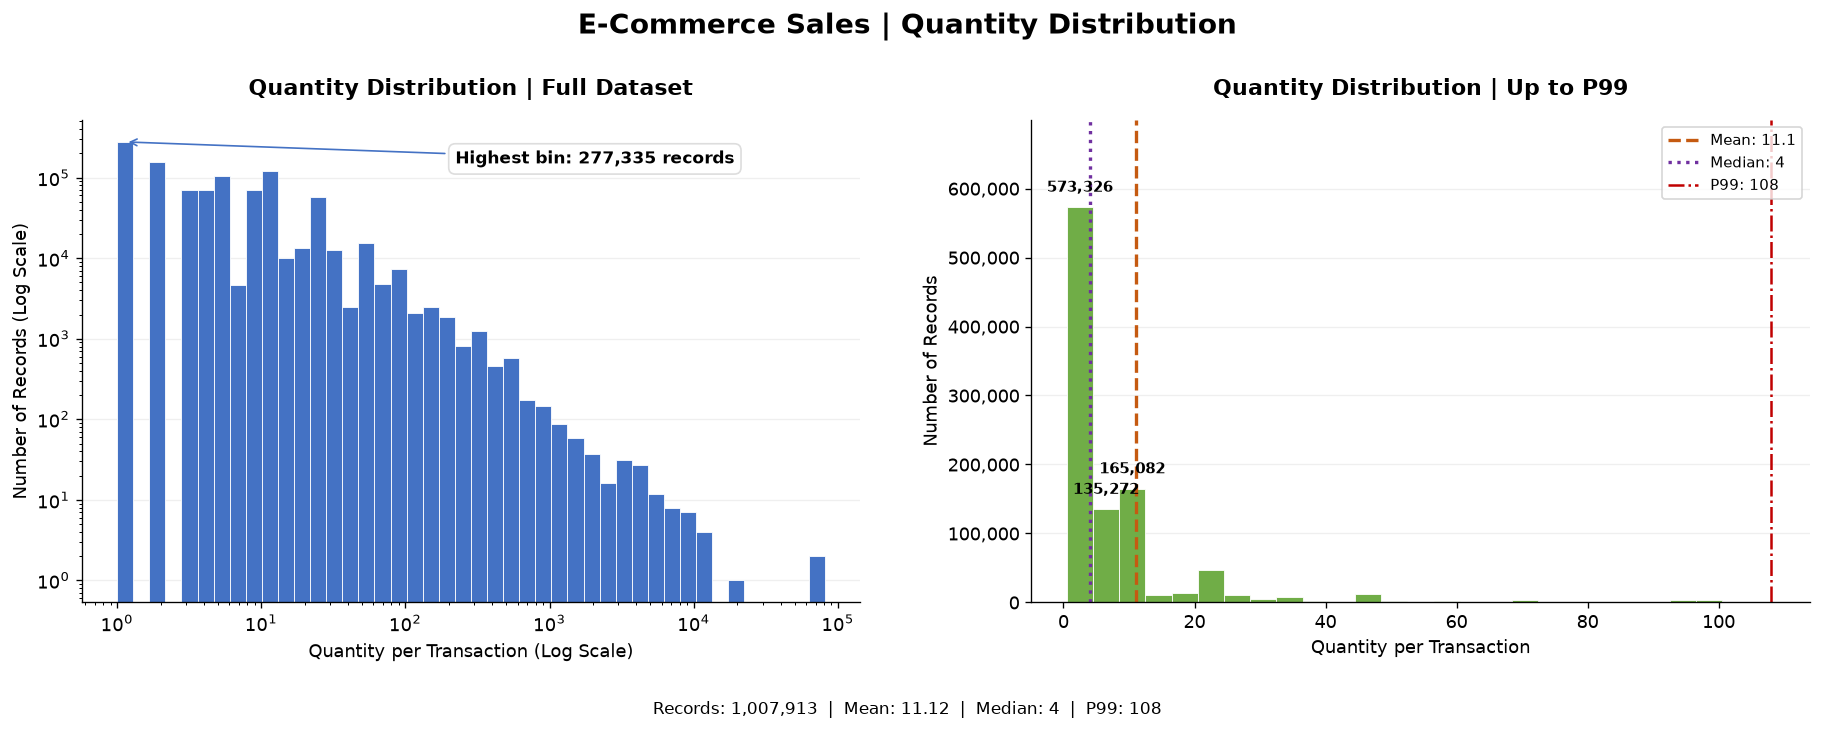

Chart saved: C:\Users\user\OneDrive\Documents\ecommerce-customer_sales-analysis-updated\ecommerce--customer-sales-analysis\images\eda_03_01_quantity_distribution.png
EDA-03-01 Visualization: COMPLETE


In [8]:

# 3. Create improved PPT-ready charts

from matplotlib.ticker import FuncFormatter
from pathlib import Path

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart A: Full quantity distribution (log-scaled bins)
log_bins = np.logspace(
    np.log10(quantity.min()),
    np.log10(quantity.max()),
    45
)

counts_full, bins_full, patches_full = axes[0].hist(
    quantity,
    bins=log_bins,
    color="#4472C4",
    edgecolor="white",
    linewidth=0.5
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[0].set_title(
    "Quantity Distribution | Full Dataset",
    fontweight="bold",
    pad=15
)
axes[0].set_xlabel("Quantity per Transaction (Log Scale)")
axes[0].set_ylabel("Number of Records (Log Scale)")

# Display the most frequent bin as an annotation
max_idx = np.argmax(counts_full)

axes[0].annotate(
    f"Highest bin: {int(counts_full[max_idx]):,} records",
    xy=(
        np.sqrt(bins_full[max_idx] * bins_full[max_idx + 1]),
        counts_full[max_idx]
    ),
    xytext=(0.48, 0.91),
    textcoords="axes fraction",
    arrowprops=dict(arrowstyle="->", color="#4472C4"),
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# Chart B: Quantity distribution up to P99
quantity_99 = quantity[quantity <= p99]

counts_99, bins_99, patches_99 = axes[1].hist(
    quantity_99,
    bins=np.arange(0.5, p99 + 2.5, 4),
    color="#70AD47",
    edgecolor="white",
    linewidth=0.5
)

axes[1].set_title(
    "Quantity Distribution | Up to P99",
    fontweight="bold",
    pad=15
)
axes[1].set_xlabel("Quantity per Transaction")
axes[1].set_ylabel("Number of Records")

axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Statistical reference lines
axes[1].axvline(
    mean_qty,
    color="#C55A11",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_qty:,.1f}"
)

axes[1].axvline(
    median_qty,
    color="#7030A0",
    linestyle=":",
    linewidth=2,
    label=f"Median: {median_qty:,.0f}"
)

axes[1].axvline(
    p99,
    color="#C00000",
    linestyle="-.",
    linewidth=1.5,
    label=f"P99: {p99:,.0f}"
)

# Label only the 3 most frequent bins
top_indices = np.argsort(counts_99)[-3:]

for i in top_indices:
    if counts_99[i] == 0:
        continue

    patch = patches_99[i]
    x = patch.get_x() + patch.get_width() / 2
    y = counts_99[i]

    axes[1].annotate(
        f"{int(y):,}",
        xy=(x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

axes[1].set_ylim(0, max(counts_99) * 1.22)
axes[1].legend(
    loc="upper right",
    fontsize=9,
    frameon=True
)

# 4. Chart styling
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "E-Commerce Sales | Quantity Distribution",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.015,
    f"Records: {len(quantity):,}  |  "
    f"Mean: {mean_qty:,.2f}  |  "
    f"Median: {median_qty:,.0f}  |  "
    f"P99: {p99:,.0f}",
    ha="center",
    fontsize=10
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.84,
    bottom=0.17,
    wspace=0.22
)

# 5. Save high-resolution chart
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "eda_03_01_quantity_distribution.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path.resolve()}")
print("EDA-03-01 Visualization: COMPLETE")


### EDA-03-01 | Interpretation

**Key Findings**

- The analysis covers 1,007,913 positive-sales transaction records.
- The mean purchase quantity is 11.12 units, compared with a median of 4 units.
- The distribution is strongly right-skewed, indicating that most transaction lines contain relatively small quantities while a limited number contain substantially larger quantities.
- The 99th percentile is 108 units, highlighting the presence of high-volume transactions in the upper tail.
- Log-scaled visualization reveals transaction patterns that are difficult to observe using a conventional linear-scale histogram.

**Business Implications**

- The median provides a more representative measure of typical transaction-line quantity than the mean.
- High-volume transactions may reflect wholesale purchasing or bulk orders and should be investigated before being classified as outliers.
- Quantity distribution should be considered when evaluating customer purchasing behavior, inventory demand, and product performance.

**Conclusion**

Sales quantities exhibit a pronounced right-skewed distribution. Further outlier assessment is necessary to distinguish potentially valid bulk purchases from unusual transactions.

### EDA-03-02 | Price Distribution Analysis

Analyze the distribution of product unit prices to identify typical price levels, distribution skewness, and unusually high-priced transactions.

The analysis uses the validated positive-sales dataset without removing potential outliers.

,Metric,Value
0,Total Records,1007913.00
1,Mean Unit Price (£),4.07
2,Median Unit Price (£),2.10
3,95th Percentile (£),9.95
4,99th Percentile (£),18.00
5,Maximum Unit Price (£),25111.09
6,Skewness,234.73
7,Records Above P99,9438.00


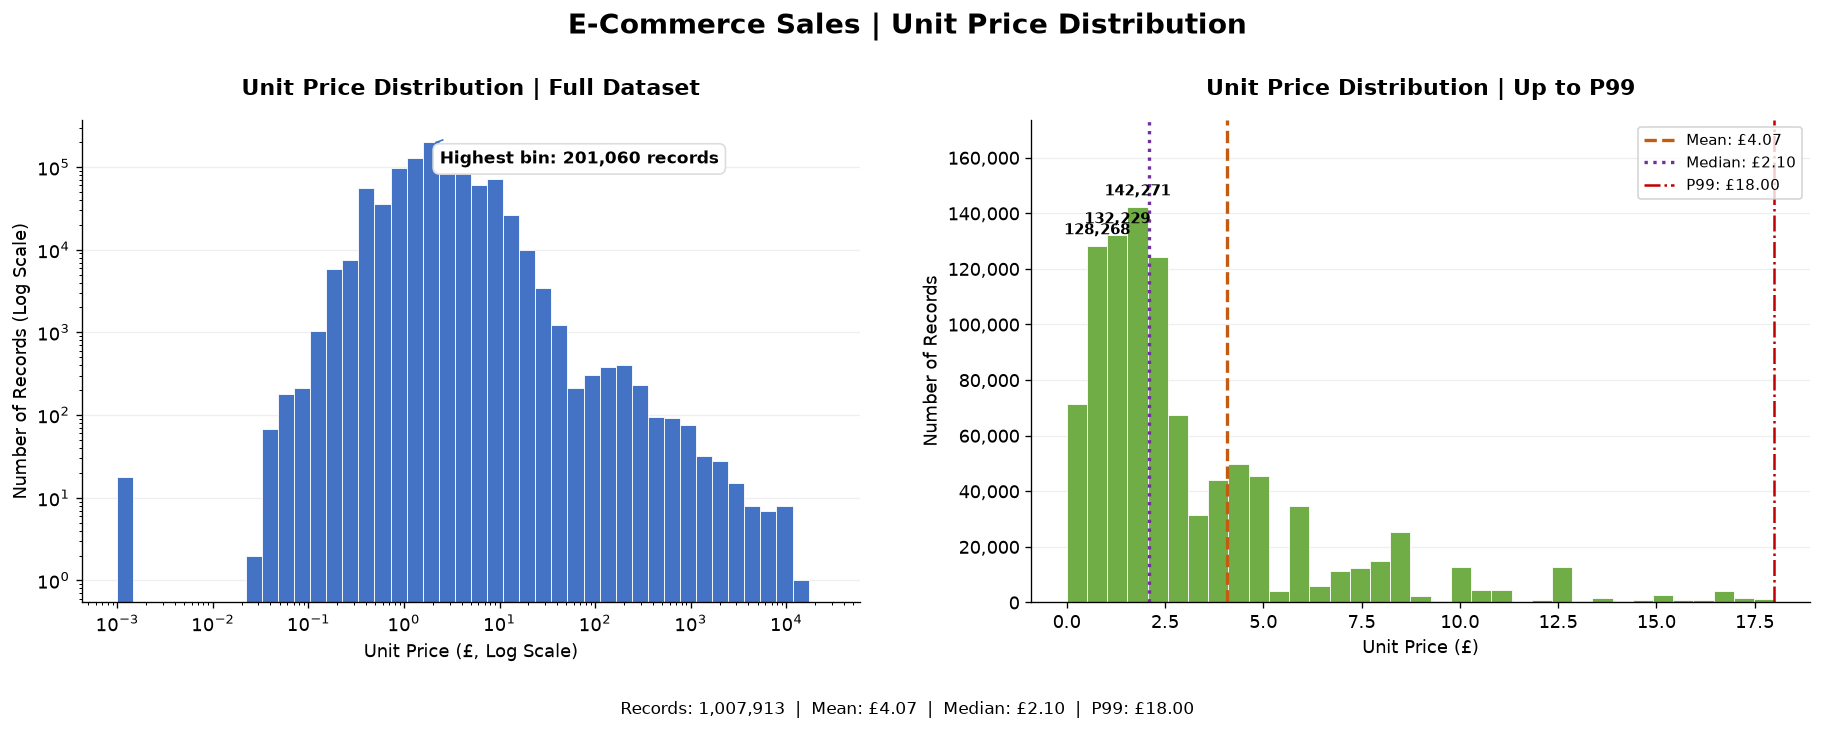

Chart saved: C:\Users\user\OneDrive\Documents\ecommerce-customer_sales-analysis-updated\ecommerce--customer-sales-analysis\images\eda_03_02_price_distribution.png
EDA-03-02 Price Distribution: COMPLETE


In [9]:

# EDA-03-02: Price Distribution Analysis
# PPT-ready charts with data labels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import FuncFormatter

# 1. Prepare data
price = sales_df["Price"].dropna()

assert (price > 0).all()

mean_price = price.mean()
median_price = price.median()
p95_price = price.quantile(0.95)
p99_price = price.quantile(0.99)
max_price = price.max()

# 2. Summary statistics
price_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Mean Unit Price (£)",
        "Median Unit Price (£)",
        "95th Percentile (£)",
        "99th Percentile (£)",
        "Maximum Unit Price (£)",
        "Skewness",
        "Records Above P99"
    ],
    "Value": [
        len(price),
        round(mean_price, 2),
        round(median_price, 2),
        round(p95_price, 2),
        round(p99_price, 2),
        round(max_price, 2),
        round(price.skew(), 2),
        int((price > p99_price).sum())
    ]
})

display(price_summary)

# 3. Create PPT-ready charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart A: Full distribution with log-scaled bins
log_bins = np.logspace(
    np.log10(price.min()),
    np.log10(price.max()),
    45
)

counts_full, bins_full, patches_full = axes[0].hist(
    price,
    bins=log_bins,
    color="#4472C4",
    edgecolor="white",
    linewidth=0.5
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[0].set_title(
    "Unit Price Distribution | Full Dataset",
    fontsize=13,
    fontweight="bold",
    pad=15
)
axes[0].set_xlabel("Unit Price (£, Log Scale)")
axes[0].set_ylabel("Number of Records (Log Scale)")

# Annotate the most frequent bin
max_idx = np.argmax(counts_full)

axes[0].annotate(
    f"Highest bin: {int(counts_full[max_idx]):,} records",
    xy=(
        np.sqrt(bins_full[max_idx] * bins_full[max_idx + 1]),
        counts_full[max_idx]
    ),
    xytext=(0.46, 0.91),
    textcoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        color="#4472C4"
    ),
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# Chart B: Distribution up to P99
price_99 = price[price <= p99_price]

counts_99, bins_99, patches_99 = axes[1].hist(
    price_99,
    bins=35,
    color="#70AD47",
    edgecolor="white",
    linewidth=0.5
)

axes[1].set_title(
    "Unit Price Distribution | Up to P99",
    fontsize=13,
    fontweight="bold",
    pad=15
)
axes[1].set_xlabel("Unit Price (£)")
axes[1].set_ylabel("Number of Records")

axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Statistical reference lines
axes[1].axvline(
    mean_price,
    color="#C55A11",
    linestyle="--",
    linewidth=2,
    label=f"Mean: £{mean_price:,.2f}"
)

axes[1].axvline(
    median_price,
    color="#7030A0",
    linestyle=":",
    linewidth=2,
    label=f"Median: £{median_price:,.2f}"
)

axes[1].axvline(
    p99_price,
    color="#C00000",
    linestyle="-.",
    linewidth=1.5,
    label=f"P99: £{p99_price:,.2f}"
)

# Add labels to the three highest bins
top_indices = np.argsort(counts_99)[-3:]

for i in top_indices:
    if counts_99[i] <= 0:
        continue

    patch = patches_99[i]
    x = patch.get_x() + patch.get_width() / 2
    y = counts_99[i]

    axes[1].annotate(
        f"{int(y):,}",
        xy=(x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

axes[1].set_ylim(0, max(counts_99) * 1.22)
axes[1].legend(loc="upper right", fontsize=9)

# 4. Styling
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "E-Commerce Sales | Unit Price Distribution",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.015,
    f"Records: {len(price):,}  |  "
    f"Mean: £{mean_price:,.2f}  |  "
    f"Median: £{median_price:,.2f}  |  "
    f"P99: £{p99_price:,.2f}",
    ha="center",
    fontsize=10
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.84,
    bottom=0.17,
    wspace=0.22
)

# 5. Save image
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "eda_03_02_price_distribution.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path.resolve()}")
print("EDA-03-02 Price Distribution: COMPLETE")


### EDA-03-02 | Interpretation

**Key Findings**

- The analysis covers 1,007,913 validated positive-sales transaction records.
- The mean unit price is £4.07, while the median is £2.10, indicating a right-skewed price distribution.
- Transaction records are concentrated in relatively low-price ranges, particularly around £1–£3.
- The 99th percentile is £18.00, meaning approximately 99% of transaction records have unit prices at or below this threshold.
- The log-scaled histogram reveals a long upper tail containing relatively infrequent high-priced transactions.

**Business Implications**

- The median unit price provides a more representative measure of the typical transaction-line price than the mean.
- Low-priced products account for a substantial share of transaction records, but their revenue contribution requires separate evaluation.
- High-priced transactions should be examined alongside purchased quantities before drawing conclusions about revenue concentration.
- Price distribution can support product assortment analysis, pricing segmentation, and further investigation of unusual transactions.

**Conclusion**

The unit price distribution is positively skewed, with transaction records concentrated at lower price points and a relatively small proportion of high-priced transactions. Further sales-value analysis is needed to determine how price and quantity jointly influence revenue.

### EDA-03-03 | Sales Value Distribution Analysis

**Objective**

Analyze transaction-line sales values to understand revenue distribution, identify high-value transaction lines, and evaluate revenue concentration.

**Analytical Approach**

- Calculate descriptive statistics for Sales (Quantity × Price).
- Compare mean, median, and upper percentiles.
- Visualize the full distribution and the distribution up to P99.
- Measure the revenue contribution of transaction lines above the 99th percentile.
- Preserve valid high-value transactions for further outlier assessment.

**Dataset:** Validated Positive Sales Dataset (1,007,913 records)

,Metric,Value
0,Total Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Mean Sales Value (£),20.32
3,Median Sales Value (£),10.08
4,95th Percentile (£),60.00
5,99th Percentile (£),184.59
6,Maximum Sales Value (£),168469.60
7,Skewness,608.61
8,Records Above P99,10080.00
9,Revenue Above P99 (£),5013543.35


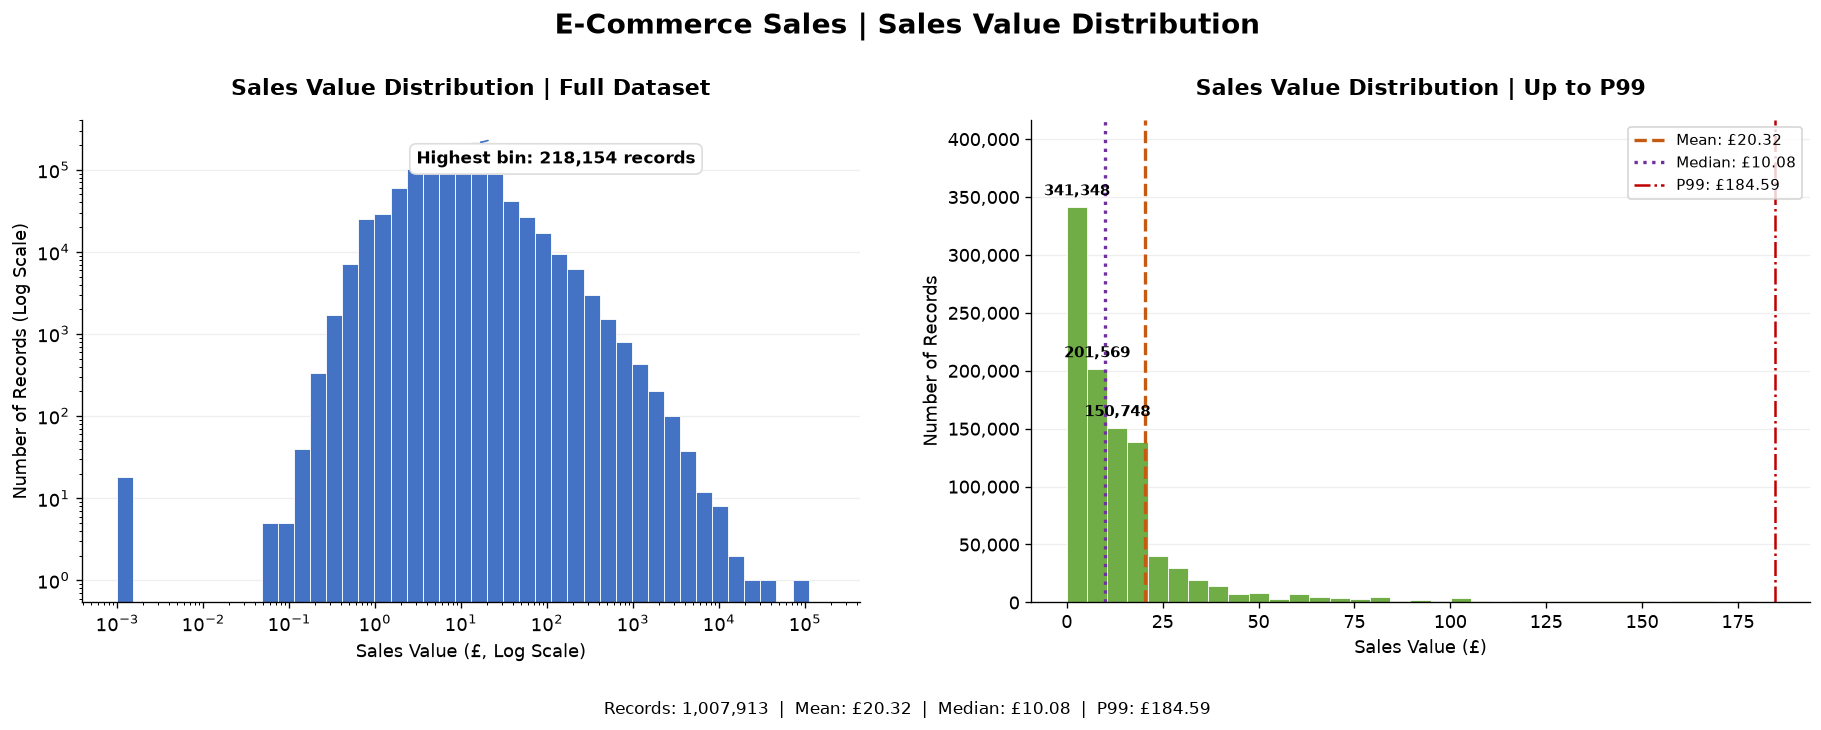

Total Revenue: £20,476,260.45
Records Above P99: 10,080
Revenue Share Above P99: 24.48%
Chart saved: C:\Users\user\OneDrive\Documents\ecommerce-customer_sales-analysis-updated\ecommerce--customer-sales-analysis\images\eda_03_03_sales_value_distribution.png
EDA-03-03 Sales Value Distribution: COMPLETE


In [10]:

# EDA-03-03 | Sales Value Distribution Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import FuncFormatter

# 1. Prepare sales data
sales = sales_df["Sales"].dropna()

assert len(sales) == 1_007_913
assert (sales > 0).all()

# 2. Calculate statistics
mean_sales = sales.mean()
median_sales = sales.median()
p95_sales = sales.quantile(0.95)
p99_sales = sales.quantile(0.99)
max_sales = sales.max()
total_revenue = sales.sum()

# Revenue concentration above P99
high_value_sales = sales[sales > p99_sales]

high_value_count = len(high_value_sales)
high_value_revenue = high_value_sales.sum()

high_value_revenue_share = (
    high_value_revenue / total_revenue * 100
)

# 3. Summary table
sales_summary = pd.DataFrame({
    "Metric": [
        "Total Sales Records",
        "Total Positive Sales Revenue (£)",
        "Mean Sales Value (£)",
        "Median Sales Value (£)",
        "95th Percentile (£)",
        "99th Percentile (£)",
        "Maximum Sales Value (£)",
        "Skewness",
        "Records Above P99",
        "Revenue Above P99 (£)",
        "Revenue Share Above P99 (%)"
    ],
    "Value": [
        len(sales),
        round(total_revenue, 2),
        round(mean_sales, 2),
        round(median_sales, 2),
        round(p95_sales, 2),
        round(p99_sales, 2),
        round(max_sales, 2),
        round(sales.skew(), 2),
        high_value_count,
        round(high_value_revenue, 2),
        round(high_value_revenue_share, 2)
    ]
})

display(sales_summary)

# 4. Create PPT-ready charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart A: Full distribution (log scale)
log_bins = np.logspace(
    np.log10(sales.min()),
    np.log10(sales.max()),
    45
)

counts_full, bins_full, _ = axes[0].hist(
    sales,
    bins=log_bins,
    color="#4472C4",
    edgecolor="white",
    linewidth=0.5
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[0].set_title(
    "Sales Value Distribution | Full Dataset",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel("Sales Value (£, Log Scale)")
axes[0].set_ylabel("Number of Records (Log Scale)")

# Label highest-frequency bin
max_idx = np.argmax(counts_full)

axes[0].annotate(
    f"Highest bin: {int(counts_full[max_idx]):,} records",
    xy=(
        np.sqrt(
            bins_full[max_idx] * bins_full[max_idx + 1]
        ),
        counts_full[max_idx]
    ),
    xytext=(0.43, 0.91),
    textcoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        color="#4472C4"
    ),
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# Chart B: Distribution up to P99
sales_99 = sales[sales <= p99_sales]

counts_99, bins_99, patches_99 = axes[1].hist(
    sales_99,
    bins=35,
    color="#70AD47",
    edgecolor="white",
    linewidth=0.5
)

axes[1].set_title(
    "Sales Value Distribution | Up to P99",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel("Sales Value (£)")
axes[1].set_ylabel("Number of Records")

axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Statistical reference lines
axes[1].axvline(
    mean_sales,
    color="#C55A11",
    linestyle="--",
    linewidth=2,
    label=f"Mean: £{mean_sales:,.2f}"
)

axes[1].axvline(
    median_sales,
    color="#7030A0",
    linestyle=":",
    linewidth=2,
    label=f"Median: £{median_sales:,.2f}"
)

axes[1].axvline(
    p99_sales,
    color="#C00000",
    linestyle="-.",
    linewidth=1.5,
    label=f"P99: £{p99_sales:,.2f}"
)

# Label top 3 frequency bins
top_indices = np.argsort(counts_99)[-3:]

for i in top_indices:
    if counts_99[i] <= 0:
        continue

    patch = patches_99[i]
    x = patch.get_x() + patch.get_width() / 2
    y = counts_99[i]

    axes[1].annotate(
        f"{int(y):,}",
        xy=(x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

axes[1].set_ylim(0, max(counts_99) * 1.22)
axes[1].legend(loc="upper right", fontsize=9)

# 5. Chart styling
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "E-Commerce Sales | Sales Value Distribution",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.015,
    f"Records: {len(sales):,}  |  "
    f"Mean: £{mean_sales:,.2f}  |  "
    f"Median: £{median_sales:,.2f}  |  "
    f"P99: £{p99_sales:,.2f}",
    ha="center",
    fontsize=10
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.84,
    bottom=0.17,
    wspace=0.22
)

# 6. Save high-resolution image
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_03_03_sales_value_distribution.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 7. Final validation
assert np.isclose(total_revenue, 20_476_260.45, atol=0.01)

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Records Above P99: {high_value_count:,}")
print(
    f"Revenue Share Above P99: "
    f"{high_value_revenue_share:.2f}%"
)
print(f"Chart saved: {output_path.resolve()}")
print("EDA-03-03 Sales Value Distribution: COMPLETE")


### EDA-03-03 | Interpretation

**Key Findings**

- The analysis covers 1,007,913 validated positive-sales transaction records, generating total positive sales revenue of £20,476,260.45.
- The mean transaction-line sales value is £20.32, while the median is £10.08.
- The distribution is strongly right-skewed, indicating that most transaction lines generate relatively small sales values, while a limited number contribute substantially larger amounts.
- The 99th percentile is £184.59, meaning approximately 99% of transaction lines have sales values at or below this threshold.
- The full-distribution chart reveals a long upper tail of high-value transaction lines.

**Business Implications**

- Median sales value provides a more representative measure of typical transaction-line revenue than the mean.
- High-value transaction lines may reflect bulk purchases, high-priced products, or a combination of both.
- Revenue concentration should be assessed by calculating the contribution of transaction lines above the 99th percentile.
- High-value transactions should not automatically be classified as anomalies without additional business-context validation.

**Conclusion**

Transaction-line sales values exhibit a pronounced right-skewed distribution. Further analysis of high-value transactions and their revenue contribution will help distinguish normal purchasing behavior from potentially unusual transactions.

### EDA-03-04 | Outlier Assessment

**Objective**

Identify and assess unusually high values in Quantity, Price, and Sales without automatically excluding potentially valid business transactions.

**Analytical Approach**

- Calculate outlier thresholds using the Interquartile Range (IQR) method.
- Compare IQR-based thresholds with the 99th percentile (P99).
- Measure the number and percentage of records exceeding each threshold.
- Investigate high-value transactions to distinguish potential business events from data quality issues.
- Document outlier handling decisions to ensure analytical transparency.

**Business Rule**

Outliers will be flagged for investigation rather than automatically removed. Valid bulk purchases and high-value transactions will be retained unless there is sufficient evidence of data errors.

In [11]:

# EDA-03-04-01 | Outlier Threshold Assessment

import numpy as np
import pandas as pd

# 1. Select analytical variables
outlier_columns = ["Quantity", "Price", "Sales"]

# 2. Calculate outlier thresholds
outlier_results = []

for col in outlier_columns:

    data = sales_df[col].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    iqr_upper = q3 + 1.5 * iqr
    p99 = data.quantile(0.99)

    # IQR outliers
    iqr_outliers = data > iqr_upper

    # P99 outliers
    p99_outliers = data > p99

    outlier_results.append({
        "Variable": col,
        "Total Records": len(data),
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "IQR Upper Bound": round(iqr_upper, 2),
        "P99 Threshold": round(p99, 2),
        "IQR Outlier Count": int(iqr_outliers.sum()),
        "IQR Outlier (%)": round(
            iqr_outliers.mean() * 100, 2
        ),
        "Above P99 Count": int(p99_outliers.sum()),
        "Above P99 (%)": round(
            p99_outliers.mean() * 100, 2
        ),
        "Maximum Value": round(data.max(), 2)
    })

# 3. Create summary table
outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.set_index("Variable").T
)

# 4. Validation
assert len(sales_df) == 1_007_913
assert (sales_df[outlier_columns] > 0).all().all()
assert outlier_summary["IQR Outlier Count"].ge(0).all()
assert outlier_summary["Above P99 Count"].ge(0).all()

print("EDA-03-04-01 Outlier Threshold Assessment: PASS")


Variable,Quantity,Price,Sales
Total Records,1007913.00,1007913.00,1007913.00
Q1,1.00,1.25,4.13
Q3,12.00,4.13,17.70
IQR,11.00,2.88,13.57
IQR Upper Bound,28.50,8.45,38.06
P99 Threshold,108.00,18.00,184.59
IQR Outlier Count,53061.00,78999.00,84954.00
IQR Outlier (%),5.26,7.84,8.43
Above P99 Count,9801.00,9438.00,10080.00
Above P99 (%),0.97,0.94,1.00


EDA-03-04-01 Outlier Threshold Assessment: PASS


### Statistical Concepts | IQR and P99

**1. Interquartile Range (IQR, 사분위범위)**

IQR measures the spread of the middle 50% of a dataset and is commonly used to identify potential outliers.

- **Q1 (First Quartile, 제1사분위수):** The 25th percentile of the data.
- **Q3 (Third Quartile, 제3사분위수):** The 75th percentile of the data.
- **IQR:** The difference between Q3 and Q1.

**Formula:**

\[
IQR = Q3 - Q1
\]

The conventional upper outlier threshold is calculated as:

\[
Upper\ Bound = Q3 + 1.5 \times IQR
\]

Values exceeding this threshold are flagged as potential outliers, not automatically classified as data errors.

**2. 99th Percentile (P99, 99백분위수)**

P99 represents the value at or below which approximately 99% of observations fall.

- Values above P99 represent approximately the highest 1% of observations.
- P99 is useful for investigating extreme transactions without assuming that they are invalid.
- The actual percentage above P99 may differ slightly from 1% due to repeated values.

**3. Application to This Project**

Both IQR and P99 are applied to Quantity, Price, and Sales to compare outlier detection thresholds.

For example, the Sales variable has:

- Q1: £4.13
- Q3: £17.70
- IQR: £13.57
- IQR Upper Bound: £38.06
- P99 Threshold: £184.59

The IQR method flags 8.43% of Sales records, whereas the P99 threshold identifies approximately 1%.

**Analytical Decision**

Outliers will be investigated rather than automatically removed because extreme values may represent legitimate bulk purchases, wholesale transactions, or high-value customer orders.

In [12]:

# EDA-03-04-02 | High-Value Transaction Investigation

import pandas as pd

# 1. Select columns for investigation
investigation_cols = [
    "Invoice",
    "StockCode",
    "Description",
    "Quantity",
    "Price",
    "Sales",
    "Customer ID",
    "Country"
]

# 2. Top 10 records by each variable
top_quantity = sales_df.nlargest(
    10, "Quantity"
)[investigation_cols].copy()

top_price = sales_df.nlargest(
    10, "Price"
)[investigation_cols].copy()

top_sales = sales_df.nlargest(
    10, "Sales"
)[investigation_cols].copy()

print("=== Top 10 by Quantity ===")
display(top_quantity)

print("=== Top 10 by Unit Price ===")
display(top_price)

print("=== Top 10 by Sales Value ===")
display(top_sales)

# 3. Revenue concentration above Sales P99
sales_p99 = sales_df["Sales"].quantile(0.99)

high_value_records = sales_df[
    sales_df["Sales"] > sales_p99
].copy()

total_revenue = sales_df["Sales"].sum()
high_value_revenue = high_value_records["Sales"].sum()

high_value_share = (
    high_value_revenue / total_revenue * 100
)

# 4. Summary
investigation_summary = pd.DataFrame({
    "Metric": [
        "Total Positive Sales Records",
        "Total Positive Sales Revenue (£)",
        "Sales P99 Threshold (£)",
        "Records Above Sales P99",
        "Revenue Above Sales P99 (£)",
        "Revenue Share Above Sales P99 (%)"
    ],
    "Value": [
        len(sales_df),
        round(total_revenue, 2),
        round(sales_p99, 2),
        len(high_value_records),
        round(high_value_revenue, 2),
        round(high_value_share, 2)
    ]
})

print("=== High-Value Revenue Concentration ===")
display(investigation_summary)

# 5. Validation
assert len(sales_df) == 1_007_913
assert len(high_value_records) == 10_080
assert high_value_share >= 0
assert high_value_share <= 100

print("EDA-03-04-02 Investigation: PASS")


=== Top 10 by Quantity ===


,Invoice,StockCode,Description,Quantity,Price,Sales,Customer ID,Country
1006438,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446,United Kingdom
542683,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346,United Kingdom
87082,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,13902,Denmark
121863,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,13902,Denmark
121865,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,13902,Denmark
121866,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,13902,Denmark
121864,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,13902,Denmark
129395,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0,17940,United Kingdom
129396,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,2500.0,17940,United Kingdom
129397,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0,17940,United Kingdom


=== Top 10 by Unit Price ===


,Invoice,StockCode,Description,Quantity,Price,Sales,Customer ID,Country
231523,512771,M,Manual,1,25111.09,25111.09,<NA>,United Kingdom
497490,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,<NA>,United Kingdom
773540,A563185,B,Adjust bad debt,1,11062.06,11062.06,<NA>,United Kingdom
129382,502263,M,Manual,1,10953.50,10953.50,12918,United Kingdom
129383,502265,M,Manual,1,10953.50,10953.50,<NA>,United Kingdom
328158,522796,M,Manual,1,10468.80,10468.80,<NA>,United Kingdom
344133,524159,M,Manual,1,10468.80,10468.80,14063,United Kingdom
357810,525399,M,Manual,1,10468.80,10468.80,<NA>,United Kingdom
71433,496115,M,Manual,1,8985.60,8985.60,17949,United Kingdom
650643,551697,POST,POSTAGE,1,8142.75,8142.75,16029,United Kingdom


=== Top 10 by Sales Value ===


,Invoice,StockCode,Description,Quantity,Price,Sales,Customer ID,Country
1006438,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446,United Kingdom
542683,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346,United Kingdom
698499,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098,United Kingdom
231523,512771,M,Manual,1,25111.09,25111.09,<NA>,United Kingdom
414827,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,15838,United Kingdom
497490,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,<NA>,United Kingdom
773540,A563185,B,Adjust bad debt,1,11062.06,11062.06,<NA>,United Kingdom
129382,502263,M,Manual,1,10953.50,10953.50,12918,United Kingdom
129383,502265,M,Manual,1,10953.50,10953.50,<NA>,United Kingdom
328158,522796,M,Manual,1,10468.80,10468.80,<NA>,United Kingdom


=== High-Value Revenue Concentration ===


,Metric,Value
0,Total Positive Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Sales P99 Threshold (£),184.59
3,Records Above Sales P99,10080.00
4,Revenue Above Sales P99 (£),5013543.35
5,Revenue Share Above Sales P99 (%),24.48


EDA-03-04-02 Investigation: PASS


### EDA-03-04-02 | Interpretation

**Key Findings**

- The top 1% of transaction lines, consisting of 10,080 records above the Sales P99 threshold (£184.59), contributed £5,013,543.35, representing 24.48% of total positive sales revenue.
- Extremely high quantities were observed in several identifiable product transactions, suggesting potential bulk or wholesale purchasing activity.
- High-value records also included non-standard entries such as Manual (M), AMAZON FEE (AMAZONFEE), Adjust bad debt (B), and POSTAGE (POST).
- These findings indicate that statistical outliers may represent different types of business activity rather than a single category of data errors.

**Business Implications**

- Legitimate high-volume product transactions should generally be retained to preserve revenue and purchasing behavior information.
- Accounting adjustments, platform fees, and shipping-related records require separate classification before product sales performance analysis.
- The current revenue concentration figure should be treated as provisional until non-product transaction types are assessed.
- Statistical thresholds alone are insufficient to distinguish valid product sales from operational or accounting entries.

**Conclusion**

High-value transaction investigation reveals a combination of potential wholesale purchases and non-standard business records. Transaction-type validation is necessary before finalizing outlier treatment and revenue analysis.

In [13]:

# EDA-03-04-03 | Special Transaction Code Assessment

special_codes = ["M", "AMAZONFEE", "B", "POST"]

special_records = sales_df[
    sales_df["StockCode"].astype(str).str.upper().isin(special_codes)
].copy()

special_summary = (
    special_records
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Sales", "size"),
        Total_Sales=("Sales", "sum"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

special_summary["Revenue_Share_Pct"] = (
    special_summary["Total_Sales"]
    / sales_df["Sales"].sum()
    * 100
).round(4)

print("=== Special Transaction Code Summary ===")
display(special_summary)

print("\n=== Overall Impact ===")
print(f"Special Records: {len(special_records):,}")
print(f"Special Sales Value: £{special_records['Sales'].sum():,.2f}")
print(
    "Share of Total Positive Sales: "
    f"{special_records['Sales'].sum() / sales_df['Sales'].sum() * 100:.2f}%"
)

# Validation
assert len(special_records) <= len(sales_df)
assert special_records["Sales"].gt(0).all()

print("\nEDA-03-04-03 Special Code Assessment: PASS")


=== Special Transaction Code Summary ===


,StockCode,Description,Records,Total_Sales,Unique_Invoices,Revenue_Share_Pct
2,M,Manual,846,339226.24,784,1.6567
3,POST,POSTAGE,1851,125682.42,1851,0.6138
0,AMAZONFEE,AMAZON FEE,3,20467.80,3,0.1000
1,B,Adjust bad debt,1,11062.06,1,0.0540
4,m,Manual,5,15.05,4,0.0001



=== Overall Impact ===
Special Records: 2,706
Special Sales Value: £496,453.57
Share of Total Positive Sales: 2.42%

EDA-03-04-03 Special Code Assessment: PASS


### EDA-03-04-03 | Interpretation

**Key Findings**

- A total of 2,706 records were identified under four special transaction code categories, including case variations of Manual (M/m).
- These records represent £496,453.57, accounting for 2.42% of total positive sales value.
- Manual entries contributed the largest share, followed by postage, Amazon fees, and bad debt adjustments.
- The relatively small number of special records has a disproportionate impact on the reported positive sales value.

**Business Implications**

- Positive Quantity and Price values alone do not guarantee that a transaction represents a product sale.
- Shipping fees, platform charges, and accounting adjustments should be distinguished from merchandise revenue.
- Manual transactions require further validation before being classified as product or non-product transactions.
- Legitimate bulk purchases should be retained even when they exceed statistical outlier thresholds.

**Outlier Handling Decision**

- **Retain:** Valid product transactions, including legitimate high-volume and high-value purchases.
- **Separate:** Identified operational and accounting-related records for dedicated analysis.
- **Review:** Manual transactions and other ambiguous transaction types.
- **Preserve:** The original positive-sales dataset for traceability and comparison.

**Conclusion**

The assessment indicates that transaction classification is more appropriate than automatic statistical outlier removal. Further validation is required before creating a product-sales-only analytical dataset.

In [14]:

# EDA-03-04-04 | Additional Special Code Discovery

# Identify stock codes containing alphabetic characters
code_series = sales_df["StockCode"].astype("string").str.upper()

alpha_code_mask = code_series.str.contains(
    r"[A-Z]", regex=True, na=False
)

alpha_records = sales_df.loc[alpha_code_mask].copy()

# Summarize by StockCode and Description
alpha_summary = (
    alpha_records
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Sales", "size"),
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

print("=== Alphabetic StockCode Investigation ===")
display(alpha_summary.head(30))

print("\n=== Summary ===")
print(f"Records with alphabetic StockCodes: {len(alpha_records):,}")
print(f"Unique StockCodes: {alpha_records['StockCode'].nunique():,}")
print(f"Sales Value: £{alpha_records['Sales'].sum():,.2f}")

print("\nEDA-03-04-04 Discovery: PASS")


=== Alphabetic StockCode Investigation ===


,StockCode,Description,Records,Total_Sales
1629,M,Manual,846,339226.24
1628,DOT,DOTCOM POSTAGE,1415,309854.11
1171,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5502,257546.20
1153,85099B,JUMBO BAG RED RETROSPOT,3287,145961.83
1631,POST,POSTAGE,1851,125682.42
1157,85099F,JUMBO BAG STRAWBERRY,1850,67985.77
1156,85099C,JUMBO BAG BAROQUE BLACK WHITE,1891,59057.61
10,15056N,EDWARDIAN PARASOL NATURAL,1040,57975.45
9,15056BL,EDWARDIAN PARASOL BLACK,869,47267.45
627,84078A,SET/4 WHITE RETRO STORAGE CUBES,328,43844.96



=== Summary ===
Records with alphabetic StockCodes: 125,868
Unique StockCodes: 1,526
Sales Value: £3,200,131.15

EDA-03-04-04 Discovery: PASS


### EDA-03-04-04 | Interpretation

**Key Findings**

- A total of 125,868 records contained alphabetic characters in their StockCodes, representing approximately 12.49% of positive-sales records.
- These records represented £3,200,131.15, or approximately 15.63% of total positive sales value.
- Many alphabetic StockCodes, such as 85123A and 85099B, corresponded to identifiable retail products.
- DOT (DOTCOM POSTAGE) was identified as an additional shipping-related transaction category, contributing £309,854.11.
- Alphabetic characters in StockCodes are therefore insufficient to distinguish merchandise from non-merchandise transactions.

**Business Implications**

- StockCode format should not be used as an automatic exclusion criterion.
- Transaction classification should consider both StockCode and Description.
- Shipping charges, platform fees, and accounting adjustments require separate treatment from merchandise sales.
- Manual entries should remain under review until their business meaning is confirmed.

**Conclusion**

The investigation supports a business-rule-based transaction classification approach rather than automatic exclusion based on StockCode patterns or statistical outlier thresholds.

In [15]:

# EDA-03-04-05 | Transaction Classification Validation

import numpy as np
import pandas as pd

# 1. Normalize StockCode
stock_code = (
    sales_df["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# 2. Define provisional business categories
conditions = [
    stock_code.isin(["POST", "DOT"]).fillna(False),
    stock_code.eq("AMAZONFEE").fillna(False),
    stock_code.eq("B").fillna(False),
    stock_code.eq("M").fillna(False)
]

categories = [
    "Shipping",
    "Platform Fee",
    "Accounting Adjustment",
    "Manual Review"
]

# 3. Create a separate classified dataset
sales_classified = sales_df.copy()

sales_classified["Transaction_Type"] = np.select(
    conditions,
    categories,
    default="Other / Unreviewed"
)

# 4. Classification summary
classification_summary = (
    sales_classified
    .groupby("Transaction_Type")
    .agg(
        Records=("Sales", "size"),
        Sales_Value=("Sales", "sum")
    )
    .reset_index()
)

classification_summary["Record_Share_Pct"] = (
    classification_summary["Records"]
    / len(sales_classified) * 100
).round(2)

classification_summary["Sales_Share_Pct"] = (
    classification_summary["Sales_Value"]
    / sales_classified["Sales"].sum() * 100
).round(2)

classification_summary["Sales_Value"] = (
    classification_summary["Sales_Value"].round(2)
)

print("=== Transaction Classification Summary ===")
display(classification_summary)

# 5. Validation
assert len(sales_classified) == len(sales_df)
assert classification_summary["Records"].sum() == len(sales_df)
assert np.isclose(
    classification_summary["Sales_Value"].sum(),
    sales_df["Sales"].sum(),
    atol=0.05
)

print("\nEDA-03-04-05 Classification Validation: PASS")


=== Transaction Classification Summary ===


,Transaction_Type,Records,Sales_Value,Record_Share_Pct,Sales_Share_Pct
0,Accounting Adjustment,1,11062.06,0.00,0.05
1,Manual Review,851,339241.29,0.08,1.66
2,Other / Unreviewed,1003792,19669952.77,99.59,96.06
3,Platform Fee,3,20467.80,0.00,0.10
4,Shipping,3266,435536.53,0.32,2.13



EDA-03-04-05 Classification Validation: PASS


### EDA-03-04-05 | Interpretation

**Key Findings**

- All 1,007,913 positive-sales records were successfully assigned to provisional transaction categories.
- Shipping-related transactions accounted for 3,266 records and £435,536.53.
- Manual entries accounted for 851 records and £339,241.29.
- Platform fees and accounting adjustments represented smaller but identifiable non-merchandise categories.
- The remaining 1,003,792 records, representing 96.06% of positive sales value, were classified as Other / Unreviewed.

**Business Implications**

- Positive sales values include both merchandise-related and operational transactions.
- Shipping fees and accounting-related entries should be separately reported when evaluating merchandise revenue.
- Manual entries require further investigation before a final inclusion or exclusion decision.
- The Other / Unreviewed category should not automatically be interpreted as verified merchandise sales.

**Outlier Handling Decision**

- **Retain:** Potentially legitimate bulk purchases and high-value product transactions.
- **Separate:** Identified shipping, platform fee, and accounting adjustment records.
- **Review:** Manual entries and other ambiguous transaction types.
- **Preserve:** The original positive-sales dataset without modifying its underlying records.

**Conclusion**

Transaction classification provides a more business-relevant approach to handling extreme values than automatic statistical outlier removal. The classification results establish a preliminary framework for merchandise-focused analysis while preserving the original dataset for auditability.

In [16]:

# EDA-03-04-06 | Final Outlier Handling Summary

import pandas as pd
import numpy as np

# 1. Outlier Threshold Summary
final_outlier_summary = outlier_summary[
    [
        "Variable",
        "IQR Upper Bound",
        "P99 Threshold",
        "IQR Outlier Count",
        "IQR Outlier (%)",
        "Above P99 Count",
        "Above P99 (%)"
    ]
].copy()

print("=== 1. Outlier Threshold Summary ===")
display(final_outlier_summary)


# 2. Revenue Concentration Summary
sales_p99 = sales_df["Sales"].quantile(0.99)

p99_records = sales_df[
    sales_df["Sales"] > sales_p99
]

revenue_concentration = pd.DataFrame({
    "Metric": [
        "Total Positive Sales Records",
        "Total Positive Sales Revenue (£)",
        "Sales P99 Threshold (£)",
        "Records Above Sales P99",
        "Revenue Above Sales P99 (£)",
        "Revenue Share Above P99 (%)"
    ],
    "Value": [
        len(sales_df),
        round(sales_df["Sales"].sum(), 2),
        round(sales_p99, 2),
        len(p99_records),
        round(p99_records["Sales"].sum(), 2),
        round(
            p99_records["Sales"].sum()
            / sales_df["Sales"].sum() * 100, 2
        )
    ]
})

print("\n=== 2. Revenue Concentration Summary ===")
display(revenue_concentration)


# 3. Transaction Classification Summary
final_classification_summary = (
    sales_classified
    .groupby("Transaction_Type")
    .agg(
        Records=("Sales", "size"),
        Sales_Value=("Sales", "sum")
    )
    .reset_index()
)

final_classification_summary["Sales_Share_Pct"] = (
    final_classification_summary["Sales_Value"]
    / sales_df["Sales"].sum() * 100
).round(2)

final_classification_summary["Sales_Value"] = (
    final_classification_summary["Sales_Value"].round(2)
)

print("\n=== 3. Transaction Classification Summary ===")
display(final_classification_summary)


# 4. Outlier Handling Decision Table
handling_decisions = pd.DataFrame({
    "Transaction Category": [
        "Potentially Valid Merchandise",
        "Shipping",
        "Platform Fee",
        "Accounting Adjustment",
        "Manual Entry",
        "Other Unreviewed Records"
    ],
    "Decision": [
        "RETAIN",
        "SEPARATE",
        "SEPARATE",
        "SEPARATE",
        "REVIEW",
        "REVIEW"
    ],
    "Rationale": [
        "Preserve potentially legitimate product sales",
        "Report shipping separately from merchandise",
        "Separate platform-related charges",
        "Separate accounting-related adjustments",
        "Verify business purpose before final treatment",
        "Requires further classification before confirmation"
    ]
})

print("\n=== 4. Outlier Handling Decision Table ===")
display(handling_decisions)


# 5. Final Data Preservation Validation
original_records = len(sales_df)
classified_records = len(sales_classified)

original_revenue = sales_df["Sales"].sum()
classified_revenue = sales_classified["Sales"].sum()

assert original_records == classified_records
assert np.isclose(
    original_revenue,
    classified_revenue,
    rtol=0,
    atol=0.01
)

assert (
    final_classification_summary["Records"].sum()
    == original_records
)

assert np.isclose(
    final_classification_summary["Sales_Value"].sum(),
    original_revenue,
    rtol=0,
    atol=0.05
)

print("\n=== 5. Final Validation ===")
print(f"Original Records: {original_records:,}")
print(f"Classified Records: {classified_records:,}")
print(f"Original Revenue: £{original_revenue:,.2f}")
print(f"Classified Revenue: £{classified_revenue:,.2f}")

print("\nEDA-03-04-06 Final Outlier Assessment: PASS")


=== 1. Outlier Threshold Summary ===


,Variable,IQR Upper Bound,P99 Threshold,IQR Outlier Count,IQR Outlier (%),Above P99 Count,Above P99 (%)
0,Quantity,28.50,108.00,53061,5.26,9801,0.97
1,Price,8.45,18.00,78999,7.84,9438,0.94
2,Sales,38.06,184.59,84954,8.43,10080,1.00



=== 2. Revenue Concentration Summary ===


,Metric,Value
0,Total Positive Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Sales P99 Threshold (£),184.59
3,Records Above Sales P99,10080.00
4,Revenue Above Sales P99 (£),5013543.35
5,Revenue Share Above P99 (%),24.48



=== 3. Transaction Classification Summary ===


,Transaction_Type,Records,Sales_Value,Sales_Share_Pct
0,Accounting Adjustment,1,11062.06,0.05
1,Manual Review,851,339241.29,1.66
2,Other / Unreviewed,1003792,19669952.77,96.06
3,Platform Fee,3,20467.80,0.10
4,Shipping,3266,435536.53,2.13



=== 4. Outlier Handling Decision Table ===


,Transaction Category,Decision,Rationale
0,Potentially Valid Merchandise,RETAIN,Preserve potentially legitimate product sales
1,Shipping,SEPARATE,Report shipping separately from merchandise
2,Platform Fee,SEPARATE,Separate platform-related charges
3,Accounting Adjustment,SEPARATE,Separate accounting-related adjustments
4,Manual Entry,REVIEW,Verify business purpose before final treatment
5,Other Unreviewed Records,REVIEW,Requires further classification before confirm...



=== 5. Final Validation ===
Original Records: 1,007,913
Classified Records: 1,007,913
Original Revenue: £20,476,260.45
Classified Revenue: £20,476,260.45

EDA-03-04-06 Final Outlier Assessment: PASS


### EDA-03-04-06 | Interpretation

**Key Findings**

- **Outlier Detection:** IQR-based outlier rates were 5.26% for Quantity, 7.84% for Price, and 8.43% for Sales.
- **Revenue Concentration:** The 10,080 transactions above the Sales P99 threshold (£184.59) contributed £5,013,543.35, representing 24.48% of total positive sales revenue.
- **Transaction Classification:** Shipping accounted for 2.13% of revenue, Manual Review for 1.66%, Platform Fee for 0.10%, and Accounting Adjustment for 0.05%.
- **Classification Limitation:** Other / Unreviewed transactions accounted for 96.06% of revenue and should not be considered fully validated merchandise sales.
- **Data Integrity:** All 1,007,913 records and £20,476,260.45 in positive sales revenue were preserved after classification.

**Outlier Handling Decisions**

- **RETAIN:** Potentially legitimate high-value merchandise transactions should not be removed solely because they exceed statistical thresholds.
- **SEPARATE:** Shipping, platform fees, and accounting adjustments should be distinguished from merchandise sales.
- **REVIEW:** Manual entries and unreviewed transactions require additional business-rule validation before final classification.

**Business Implications**

The results indicate substantial revenue concentration among high-value transactions. Statistical outliers may represent legitimate wholesale orders or special business transactions rather than data errors.

For subsequent sales performance analysis, Positive Sales Revenue should be distinguished from Merchandise Sales Revenue to avoid overstating product-related sales.

**Final Assessment: PASS**

The outlier assessment and transaction classification reconciliation were completed successfully. No records or revenue were lost during classification. Further transaction-level review is required before finalizing merchandise-only revenue.

## EDA-03-05 | Merchandise Sales Dataset Preparation

### Objective

Prepare a merchandise sales dataset for subsequent sales performance analysis by separating identifiable non-merchandise transactions from positive sales records.

The analysis will preserve the original Positive Sales Dataset while applying transparent business rules to create a provisional Merchandise Sales Dataset.

### EDA-03-05-01 | Transaction Classification Review

**Classification Principles**

- **Merchandise Candidates:** Retain transactions not identified as special non-merchandise records, subject to further validation.
- **Shipping:** Separate shipping and postage charges from merchandise revenue.
- **Platform Fees:** Separate platform-related fees.
- **Accounting Adjustments:** Exclude identifiable accounting adjustments from merchandise revenue.
- **Manual Review:** Keep manual entries separate until their business purpose is verified.

**Validation Requirements**

- Preserve all original records.
- Ensure that each transaction belongs to exactly one classification category.
- Reconcile total record counts and revenue.
- Clearly distinguish provisional merchandise revenue from validated merchandise revenue.

In [17]:

# EDA-03-05-01 | Transaction Classification Review

classification_review = (
    sales_classified
    .groupby("Transaction_Type", dropna=False)
    .agg(
        Records=("Sales", "size"),
        Revenue=("Sales", "sum")
    )
    .reset_index()
)

classification_review["Record_Share_Pct"] = (
    classification_review["Records"]
    / len(sales_classified) * 100
).round(2)

classification_review["Revenue_Share_Pct"] = (
    classification_review["Revenue"]
    / sales_classified["Sales"].sum() * 100
).round(2)

classification_review["Revenue"] = (
    classification_review["Revenue"].round(2)
)

display(
    classification_review.sort_values(
        "Revenue", ascending=False
    )
)

# Validation
assert len(sales_classified) == len(sales_df)
assert sales_classified["Transaction_Type"].notna().all()

print("\nEDA-03-05-01 Classification Review: PASS")


,Transaction_Type,Records,Revenue,Record_Share_Pct,Revenue_Share_Pct
2,Other / Unreviewed,1003792,19669952.77,99.59,96.06
4,Shipping,3266,435536.53,0.32,2.13
1,Manual Review,851,339241.29,0.08,1.66
3,Platform Fee,3,20467.80,0.00,0.10
0,Accounting Adjustment,1,11062.06,0.00,0.05



EDA-03-05-01 Classification Review: PASS


In [18]:

# EDA-03-05-02 | Provisional Merchandise Sales Dataset

import numpy as np
import pandas as pd

# 1. Preserve original classified dataset
merchandise_sales_df = sales_classified.loc[
    sales_classified["Transaction_Type"] == "Other / Unreviewed"
].copy()

# 2. Separate special transactions
excluded_sales_df = sales_classified.loc[
    sales_classified["Transaction_Type"] != "Other / Unreviewed"
].copy()

# 3. Dataset comparison
dataset_comparison = pd.DataFrame({
    "Dataset": [
        "Positive Sales",
        "Provisional Merchandise Sales",
        "Separated Special Transactions"
    ],
    "Records": [
        len(sales_df),
        len(merchandise_sales_df),
        len(excluded_sales_df)
    ],
    "Revenue_GBP": [
        sales_df["Sales"].sum(),
        merchandise_sales_df["Sales"].sum(),
        excluded_sales_df["Sales"].sum()
    ]
})

dataset_comparison["Record_Share_Pct"] = (
    dataset_comparison["Records"]
    / len(sales_df) * 100
).round(2)

dataset_comparison["Revenue_Share_Pct"] = (
    dataset_comparison["Revenue_GBP"]
    / sales_df["Sales"].sum() * 100
).round(2)

dataset_comparison["Revenue_GBP"] = (
    dataset_comparison["Revenue_GBP"].round(2)
)

print("=== Dataset Comparison ===")
display(dataset_comparison)

# 4. Data integrity validation
assert (
    len(merchandise_sales_df) + len(excluded_sales_df)
    == len(sales_df)
)

assert np.isclose(
    merchandise_sales_df["Sales"].sum()
    + excluded_sales_df["Sales"].sum(),
    sales_df["Sales"].sum(),
    rtol=0,
    atol=0.01
)

assert merchandise_sales_df["Transaction_Type"].eq(
    "Other / Unreviewed"
).all()

print("\nEDA-03-05-02 Dataset Creation: PASS")


=== Dataset Comparison ===


,Dataset,Records,Revenue_GBP,Record_Share_Pct,Revenue_Share_Pct
0,Positive Sales,1007913,20476260.45,100.00,100.00
1,Provisional Merchandise Sales,1003792,19669952.77,99.59,96.06
2,Separated Special Transactions,4121,806307.68,0.41,3.94



EDA-03-05-02 Dataset Creation: PASS


=== Revenue Impact Summary ===


,Metric,Value
0,Positive Sales Revenue,20476260.45
1,Provisional Merchandise Revenue,19669952.77
2,Separated Special Transaction Value,806307.68
3,Revenue Difference (%),3.94


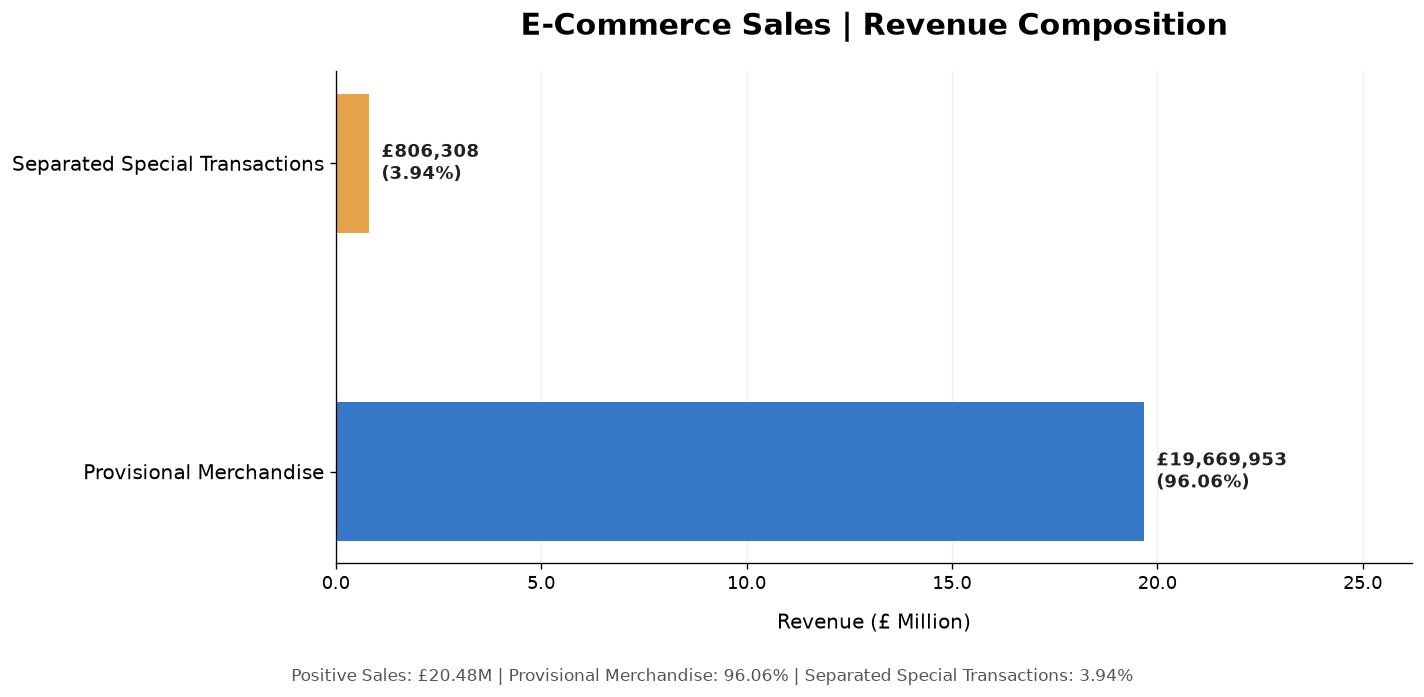


Chart saved: ..\images\eda_03_05_revenue_composition.png

EDA-03-05-03 Revenue Impact Analysis: PASS


In [21]:


# EDA-03-05-03 | Revenue Impact Analysis
# Revised Version: PPT-ready chart with GBP Million axis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# --------------------------------------------------
# 1. Revenue Impact Summary
# --------------------------------------------------

positive_revenue = sales_df["Sales"].sum()
provisional_revenue = merchandise_sales_df["Sales"].sum()
separated_revenue = excluded_sales_df["Sales"].sum()

revenue_impact = pd.DataFrame({
    "Metric": [
        "Positive Sales Revenue",
        "Provisional Merchandise Revenue",
        "Separated Special Transaction Value",
        "Revenue Difference (%)"
    ],
    "Value": [
        round(positive_revenue, 2),
        round(provisional_revenue, 2),
        round(separated_revenue, 2),
        round(separated_revenue / positive_revenue * 100, 2)
    ]
})

print("=== Revenue Impact Summary ===")
display(revenue_impact)


# --------------------------------------------------
# 2. Revenue Composition Chart
# --------------------------------------------------

categories = [
    "Provisional Merchandise",
    "Separated Special Transactions"
]

values = [
    provisional_revenue,
    separated_revenue
]

colors = ["#3777C8", "#E6A34A"]

fig, ax = plt.subplots(figsize=(12, 5.8))

bars = ax.barh(
    categories,
    values,
    color=colors,
    height=0.45
)

# Data labels: Revenue and Percentage
for bar, value in zip(bars, values):

    revenue_label = f"£{value:,.0f}"
    percentage_label = (
        f"{value / positive_revenue * 100:.2f}%"
    )

    ax.text(
        bar.get_width() + positive_revenue * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{revenue_label}\n({percentage_label})",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        color="#222222"
    )

# --------------------------------------------------
# 3. Axis Formatting
# --------------------------------------------------

ax.set_xlim(
    0,
    positive_revenue * 1.28
)

# Convert axis values to GBP Million
ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x / 1_000_000:.1f}"
    )
)

ax.set_xlabel(
    "Revenue (£ Million)",
    fontsize=12,
    labelpad=12
)

ax.tick_params(
    axis="x",
    labelsize=11
)

ax.tick_params(
    axis="y",
    labelsize=12
)

# --------------------------------------------------
# 4. Chart Styling
# --------------------------------------------------

ax.set_title(
    "E-Commerce Sales | Revenue Composition",
    fontsize=18,
    fontweight="bold",
    pad=22
)

ax.grid(
    axis="x",
    linestyle="-",
    alpha=0.20
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add summary note
fig.text(
    0.5,
    0.01,
    "Positive Sales: £20.48M | "
    "Provisional Merchandise: 96.06% | "
    "Separated Special Transactions: 3.94%",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)


# --------------------------------------------------
# 5. Save Chart for PPT
# --------------------------------------------------

output_dir = Path("../images")
output_dir.mkdir(
    parents=True,
    exist_ok=True
)

chart_path = (
    output_dir /
    "eda_03_05_revenue_composition.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"\nChart saved: {chart_path}")


# --------------------------------------------------
# 6. Revenue Reconciliation Validation
# --------------------------------------------------

assert np.isclose(
    provisional_revenue + separated_revenue,
    positive_revenue,
    rtol=0,
    atol=0.01
)

assert (
    len(merchandise_sales_df)
    + len(excluded_sales_df)
    == len(sales_df)
)

print(
    "\nEDA-03-05-03 Revenue Impact Analysis: PASS"
)


In [22]:

# EDA-03-05-04 | Data Integrity Validation

import pandas as pd
import numpy as np

# 1. Record Reconciliation
record_check = (
    len(merchandise_sales_df)
    + len(excluded_sales_df)
    == len(sales_df)
)

# 2. Revenue Reconciliation
revenue_check = np.isclose(
    merchandise_sales_df["Sales"].sum()
    + excluded_sales_df["Sales"].sum(),
    sales_df["Sales"].sum(),
    rtol=0,
    atol=0.01
)

# 3. Dataset Partition Validation
overlap_count = len(
    merchandise_sales_df.index.intersection(
        excluded_sales_df.index
    )
)

partition_check = (
    overlap_count == 0
    and merchandise_sales_df.index.is_unique
    and excluded_sales_df.index.is_unique
    and sales_classified.index.is_unique
)

# 4. Positive Quantity and Price
quantity_check = (
    merchandise_sales_df["Quantity"] > 0
).all()

price_check = (
    merchandise_sales_df["Price"] > 0
).all()

# 5. Sales Calculation Validation
sales_check = np.isclose(
    merchandise_sales_df["Sales"],
    merchandise_sales_df["Quantity"]
    * merchandise_sales_df["Price"],
    rtol=1e-9,
    atol=0.01
).all()

# 6. Customer ID Completeness
missing_customer_ids = (
    merchandise_sales_df["Customer ID"].isna().sum()
)

missing_customer_pct = (
    missing_customer_ids
    / len(merchandise_sales_df) * 100
)

# 7. Validation Summary
validation_results = pd.DataFrame({
    "Validation": [
        "Record Reconciliation",
        "Revenue Reconciliation",
        "Dataset Partition",
        "Positive Quantity",
        "Positive Price",
        "Sales Calculation"
    ],
    "Status": [
        record_check,
        revenue_check,
        partition_check,
        quantity_check,
        price_check,
        sales_check
    ]
})

validation_results["Result"] = (
    validation_results["Status"]
    .map({True: "PASS", False: "FAIL"})
)

print("=== Data Integrity Validation ===")
display(validation_results[["Validation", "Result"]])

print("\n=== Customer ID Completeness ===")
print(f"Missing Customer IDs: {missing_customer_ids:,}")
print(f"Missing Customer ID Rate: {missing_customer_pct:.2f}%")
print(f"Overlapping Records: {overlap_count:,}")

assert validation_results["Status"].all(), (
    "EDA-03-05-04: One or more validations failed."
)

print("\nEDA-03-05-04 Data Integrity Validation: PASS")


=== Data Integrity Validation ===


,Validation,Result
0,Record Reconciliation,PASS
1,Revenue Reconciliation,PASS
2,Dataset Partition,PASS
3,Positive Quantity,PASS
4,Positive Price,PASS
5,Sales Calculation,PASS



=== Customer ID Completeness ===
Missing Customer IDs: 226,867
Missing Customer ID Rate: 22.60%
Overlapping Records: 0

EDA-03-05-04 Data Integrity Validation: PASS


### EDA-03-05-04 | Interpretation

**Key Findings**

- All six data integrity validation checks passed successfully.
- Record and revenue reconciliation confirmed consistency between the original positive-sales dataset and the separated datasets.
- No overlapping records were detected between the merchandise and special transaction datasets.
- All merchandise records contain positive quantities and unit prices, and their Sales values match the calculated transaction values.
- A total of **226,867 records (22.60%)** have missing Customer IDs.

**Analytical Implications**

- The separated datasets maintain numerical consistency with the original positive-sales dataset.
- The provisional merchandise dataset can be used for subsequent exploratory analysis, subject to further review of unclassified transactions.
- Customer-level analyses, including RFM segmentation, should exclude records with missing Customer IDs.
- Special transactions should remain separately identifiable to avoid mixing merchandise revenue with shipping fees, platform charges, and accounting adjustments.

**Conclusion**

EDA-03-05-04 Data Integrity Validation: **PASS**

The dataset reconciliation and integrity checks were completed successfully.

In [23]:

# EDA-03-05-05 | Final Dataset Summary & Readiness Assessment

import pandas as pd
import numpy as np

# 1. Dataset Summary
final_dataset_summary = pd.DataFrame({
    "Dataset": [
        "Positive Sales",
        "Provisional Merchandise",
        "Separated Special Transactions"
    ],
    "Records": [
        len(sales_df),
        len(merchandise_sales_df),
        len(excluded_sales_df)
    ],
    "Revenue_GBP": [
        sales_df["Sales"].sum(),
        merchandise_sales_df["Sales"].sum(),
        excluded_sales_df["Sales"].sum()
    ]
})

total_records = len(sales_df)
total_revenue = sales_df["Sales"].sum()

final_dataset_summary["Record_Share_Pct"] = (
    final_dataset_summary["Records"]
    / total_records * 100
).round(2)

final_dataset_summary["Revenue_Share_Pct"] = (
    final_dataset_summary["Revenue_GBP"]
    / total_revenue * 100
).round(2)

print("=== 1. Final Dataset Summary ===")
display(
    final_dataset_summary.style.format({
        "Records": "{:,.0f}",
        "Revenue_GBP": "£{:,.2f}",
        "Record_Share_Pct": "{:.2f}%",
        "Revenue_Share_Pct": "{:.2f}%"
    })
)

# 2. Customer ID Readiness
customer_readiness = pd.DataFrame({
    "Metric": [
        "Merchandise Records",
        "Records with Customer ID",
        "Missing Customer IDs",
        "Missing Customer ID Rate (%)",
        "Unique Identifiable Customers"
    ],
    "Value": [
        len(merchandise_sales_df),
        merchandise_sales_df["Customer ID"].notna().sum(),
        merchandise_sales_df["Customer ID"].isna().sum(),
        round(
            merchandise_sales_df["Customer ID"].isna().mean()
            * 100, 2
        ),
        merchandise_sales_df["Customer ID"].nunique()
    ]
})

print("\n=== 2. Customer Analysis Readiness ===")
display(customer_readiness)

# 3. Final Reconciliation
records_pass = (
    len(merchandise_sales_df)
    + len(excluded_sales_df)
    == len(sales_df)
)

revenue_pass = np.isclose(
    merchandise_sales_df["Sales"].sum()
    + excluded_sales_df["Sales"].sum(),
    sales_df["Sales"].sum(),
    rtol=0,
    atol=0.01
)

final_pass = records_pass and revenue_pass

print("\n=== 3. Final Readiness Assessment ===")
print(f"Record Reconciliation: {'PASS' if records_pass else 'FAIL'}")
print(f"Revenue Reconciliation: {'PASS' if revenue_pass else 'FAIL'}")

assert final_pass, "Final dataset reconciliation failed."

print("\nEDA-03-05-05 Final Dataset Readiness: PASS")
print("Ready for EDA-04, subject to provisional classification.")


=== 1. Final Dataset Summary ===


,Dataset,Records,Revenue_GBP,Record_Share_Pct,Revenue_Share_Pct
0,Positive Sales,"1,007,913","£20,476,260.45",100.00%,100.00%
1,Provisional Merchandise,"1,003,792","£19,669,952.77",99.59%,96.06%
2,Separated Special Transactions,"4,121","£806,307.68",0.41%,3.94%



=== 2. Customer Analysis Readiness ===


,Metric,Value
0,Merchandise Records,1003792.0
1,Records with Customer ID,776925.0
2,Missing Customer IDs,226867.0
3,Missing Customer ID Rate (%),22.6
4,Unique Identifiable Customers,5862.0



=== 3. Final Readiness Assessment ===
Record Reconciliation: PASS
Revenue Reconciliation: PASS

EDA-03-05-05 Final Dataset Readiness: PASS
Ready for EDA-04, subject to provisional classification.


### EDA-03-05-05 | Final Interpretation

**Key Findings**

- The positive-sales dataset contains **1,007,913 records**, representing **£20.48 million** in positive transaction value.
- Provisional merchandise transactions account for **96.06%** of positive sales value.
- Special transactions account for **3.94%**, including shipping, platform fees, manual entries, and accounting adjustments.
- Record-level and revenue reconciliation checks confirmed that the separated datasets preserve the original positive-sales totals.
- Missing Customer IDs remain an important limitation for customer-level analysis.

**Analytical Decisions**

1. **Sales Performance Analysis:** Use the provisional merchandise dataset to analyze product-related sales performance.
2. **Special Transaction Analysis:** Keep shipping, platform fees, accounting adjustments, and manual-review transactions separately identifiable.
3. **Customer Segmentation:** Exclude transactions with missing Customer IDs when conducting RFM analysis.
4. **Outlier Treatment:** Retain extreme values unless there is sufficient evidence that they represent invalid transactions.
5. **Classification Limitation:** Treat unreviewed transactions as provisionally classified rather than confirmed merchandise sales.

**Business Implications**

- Separating identifiable non-merchandise transactions reduces distortion in product-related revenue analysis.
- Preserving high-value transactions allows the analysis to capture potential wholesale and bulk-purchasing behavior.
- Customer ID completeness determines which records can be used for customer-level segmentation.
- Further transaction classification would improve the reliability of merchandise revenue reporting.

**Conclusion**

EDA-03-05 provides a reconciled and documented foundation for subsequent sales performance analysis.

The provisional merchandise dataset is ready for exploratory analysis, with classification limitations explicitly documented.

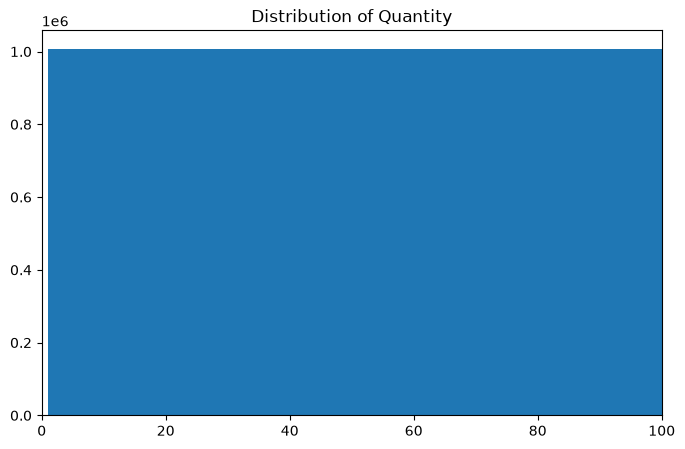

In [22]:
# 1-3-2 Quantity Histogram (X축 범위를 100까지 제한)

plt.figure(figsize=(8,5))

plt.hist(sales_df["Quantity"], bins=50)

plt.xlim(0,100)

plt.title("Distribution of Quantity")

plt.show()

## Distribution of Transaction Sales

Transaction values are highly concentrated at lower sales amounts.

Only a small proportion of transactions generate exceptionally high revenue.

## Business Insight

The majority of transactions are low-value purchases, while a relatively small number of large transactions account for a significant share of revenue. This pattern is common in retail and hightlights the importance of identifying high-value customers. 

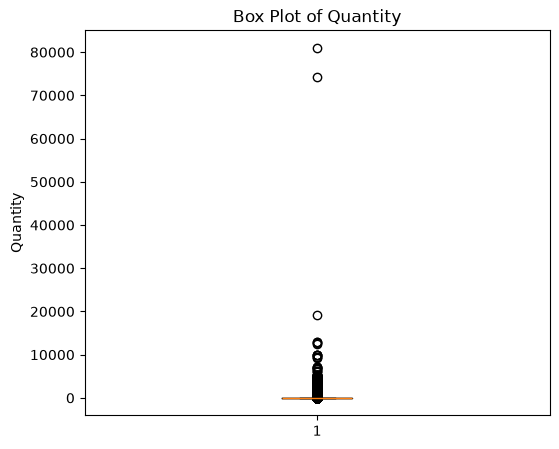

In [23]:
# 2-1 Quantity Box Plot

plt.figure(figsize=(6,5))
plt.boxplot(sales_df["Quantity"])
plt.title("Box Plot of Quantity")
plt.ylabel("Quantity")
plt.show()

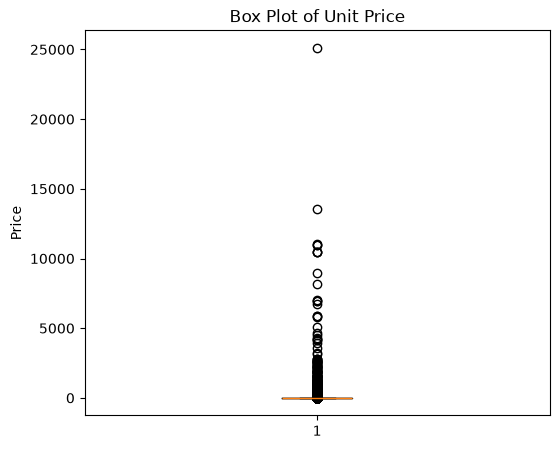

In [24]:
#2-2 Price Box Plot

plt.figure(figsize=(6,5))

plt.boxplot(sales_df["Price"])

plt.title("Box Plot of Unit Price")

plt.ylabel("Price")

plt.show()

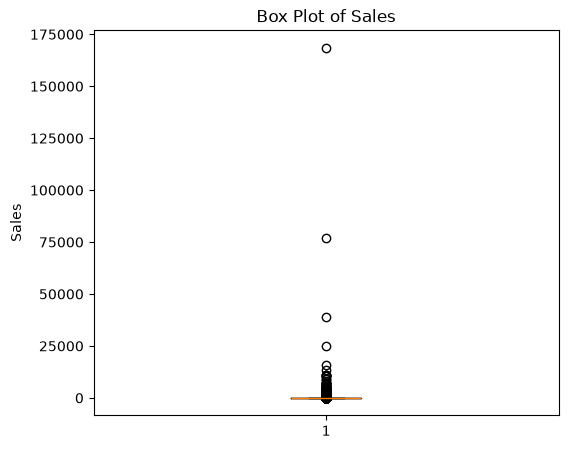

In [25]:
#2-3 Sales Box Plot

plt.figure(figsize=(6,5))

plt.boxplot(sales_df["Sales"])

plt.title("Box Plot of Sales")

plt.ylabel("Sales")

plt.show()

### Box Plot Analysis 

Box plots were used to examine the distribution of Quantity, Price, and Sales while identifying protential outliers.

All three variables exhibit strong right-skewed distributions with numerous observations beyond the upper whisker. These extreme values are consistent with the histogram analysis and likely represent meaningful business events such as bulk purchases, premium-priced products, or high-value customer transactions rather than data errors. 

In [26]:
# 2-4 Outlier Investigation: Sales

sales_df.nlargest(10, "Sales")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sales
1026519,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.60
554116,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.60
713089,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.0,United Kingdom,38970.00
236866,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,25111.09
424077,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838.0,United Kingdom,15818.40
507980,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33
789630,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06
132260,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom,10953.50
132262,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,NaN,United Kingdom,10953.50
335624,522796,M,Manual,1,2010-09-16 15:12:00,10468.80,NaN,United Kingdom,10468.80


In [27]:
# 2-4 Outlier Investigation: Quantity

sales_df.nlargest(10, "Quantity")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sales
1026519,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6
554116,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.6
89033,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark,1915.2
124582,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,1296.0
124584,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,1296.0
124585,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark,1274.4
124583,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark,1248.0
132274,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0
132275,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0
132276,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0


In [28]:
# 2-4 Outlier Investigation: Price
sales_df.nlargest(10, "Price") 

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sales
236866,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,25111.09
507980,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33
789630,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06
132260,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom,10953.50
132262,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,NaN,United Kingdom,10953.50
335624,522796,M,Manual,1,2010-09-16 15:12:00,10468.80,NaN,United Kingdom,10468.80
351868,524159,M,Manual,1,2010-09-27 16:12:00,10468.80,14063.0,United Kingdom,10468.80
365860,525399,M,Manual,1,2010-10-05 11:49:00,10468.80,NaN,United Kingdom,10468.80
73095,496115,M,Manual,1,2010-01-29 11:04:00,8985.60,17949.0,United Kingdom,8985.60
664336,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,16029.0,United Kingdom,8142.75


### Outlier Investigation

The largest Quantity transactions were associated with bulk purchases, suggesting legitimate wholesales or business orders.

The highest Price observations primarily consisted of manual adjustments, administrative charges, and accounting-related records such as "Manual", "AMAZON FEE", and "Adjust bad debt".

The highest Sales transactions were mainly driven by extremely large purchase quantities rather than usually expensive products.

These findings indicate that not all outliers should be treated as data errors. Instead, they represent different business scenarios that should be analyzed separately.

In [29]:
# 3-1. Daily Sales Trend 
# 1) Create Date column

sales_df["Date"] = sales_df["InvoiceDate"].dt.date

In [30]:
# 2) Calculte Daily Sales

daily_sales = (
    sales_df
    .groupby("Date")["Sales"]
    .sum()
    .reset_index()
)

daily_sales.head()

,Date,Sales
0,2009-12-01,54351.23
1,2009-12-02,63172.58
2,2009-12-03,73972.45
3,2009-12-04,40582.32
4,2009-12-05,9803.05


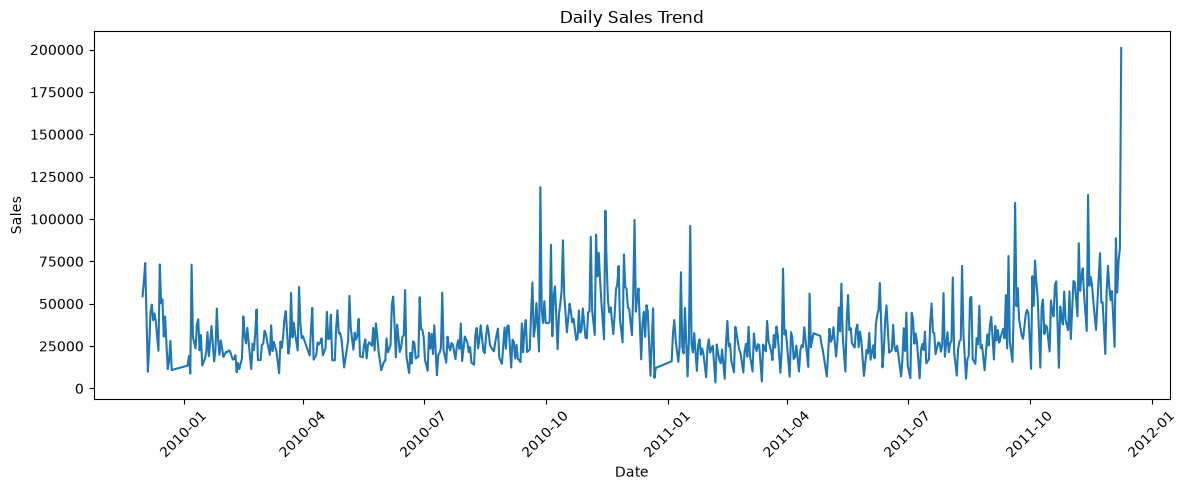

In [31]:
# 3) Create Line Chart of Daily Sales
plt.figure(figsize=(12,5))

plt.plot(
    daily_sales["Date"],
    daily_sales["Sales"]
)

plt.title ("Daily Sales Trend")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Daily Sales Trend

Daily sales were aggreated to examine overall revenue trends over time.

The line chart provides and overview of fluctuations in daily sales and helps identify periods of unusually high or low sales activity. 

Daily sales fluctuate substantially throughtout the observation period.

Despite the high day-to-day variability, the overall trend suggests increasing sales toward the end of 2011.

A pronounced sales spike is observed near the end of the dataset, which is consistent with the bulk purchase transactions identified during the outlier investigation. 

The daily trend also indicates a possbile seasonal increase in sales during the final months of the year.

In [32]:
# 3-2 Monthly Sales Trend
# 1) Create Month Column

sales_df["Month"]= sales_df["InvoiceDate"].dt.to_period("M")

In [33]:
# 2) Aggregate Monthly Sales

monthly_sales = (
    sales_df
    .groupby("Month")["Sales"]
    .sum()
    .reset_index()
)

In [34]:
#3) Convert formatting 

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

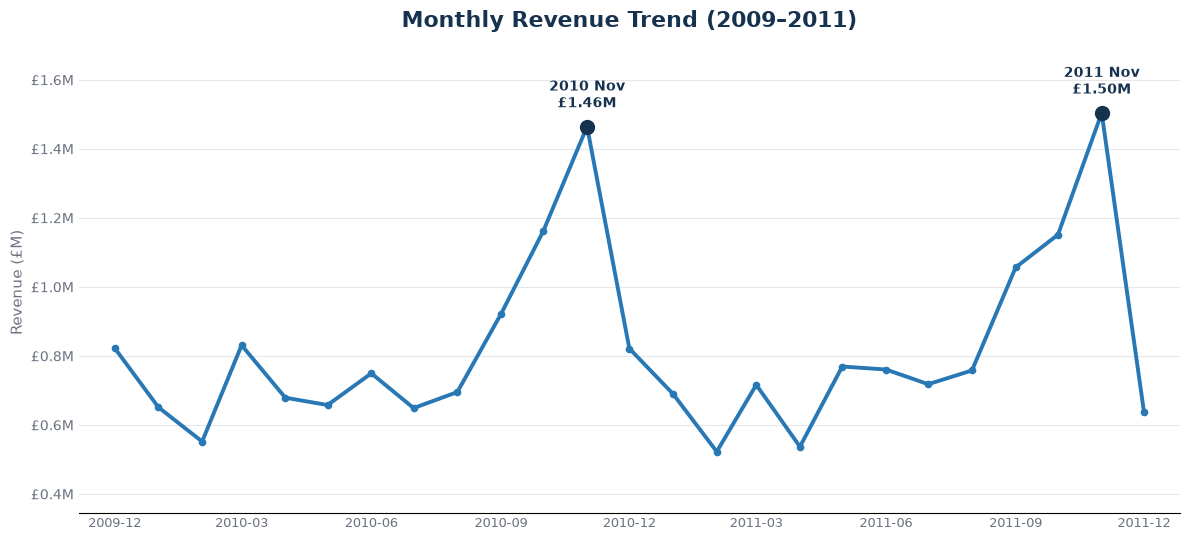

Chart saved: ..\images\monthly_sales_trend_ppt.png


In [35]:
# 4) Monthly Sales Trend


import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from pathlib import Path

# 1. Prepare monthly sales data
plot_df = monthly_sales[["Month", "Sales"]].copy()
plot_df["Month"] = pd.to_datetime(plot_df["Month"].astype(str))
plot_df = plot_df.sort_values("Month").reset_index(drop=True)

# 2. Identify November peaks
nov_peaks = plot_df[
    (plot_df["Month"].dt.month == 11) &
    (plot_df["Month"].dt.year.isin([2010, 2011]))
]

# 3. Create presentation chart
fig, ax = plt.subplots(figsize=(12, 5.5))

navy = "#16324F"
blue = "#2878B5"
gray = "#6B7280"

ax.plot(
    plot_df["Month"],
    plot_df["Sales"],
    color=blue,
    linewidth=2.8,
    marker="o",
    markersize=4.5
)

# 4. Highlight November peaks
ax.scatter(
    nov_peaks["Month"],
    nov_peaks["Sales"],
    color=navy,
    s=100,
    zorder=5
)

for _, row in nov_peaks.iterrows():
    ax.annotate(
        f'{row["Month"].year} Nov\n'
        f'£{row["Sales"]/1_000_000:.2f}M',
        (row["Month"], row["Sales"]),
        xytext=(0, 14),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=navy
    )

# 5. Format axes
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, pos: f"£{x/1_000_000:.1f}M"
    )
)

ticks = plot_df["Month"].iloc[::3]
ax.set_xticks(ticks)
ax.set_xticklabels(
    ticks.dt.strftime("%Y-%m"),
    rotation=0,
    fontsize=9
)

ax.set_title(
    "Monthly Revenue Trend (2009–2011)",
    fontsize=16,
    fontweight="bold",
    color=navy,
    pad=18
)

ax.set_ylabel("Revenue (£M)", fontsize=11, color=gray)
ax.set_xlabel("")

# 6. Clean visual style
ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="both", length=0, colors=gray)
ax.margins(x=0.035, y=0.18)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()

# 7. Save before displaying
output_path = Path("../images/monthly_sales_trend_ppt.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")



### Sales Performance KPI Summary

In [81]:
import pandas as pd

# 현재 Notebook에 존재하는 DataFrame 확인
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

__: (10, 9)
___: (10, 9)
df: (1028001, 8)
_1: (5, 8)
_4: (8, 4)
_5: (4, 4)
negative_qty: (19103, 8)
_8: (10, 8)
negative_price: (5, 8)
_10: (5, 8)
zero_price: (979, 8)
_12: (10, 8)
_14: (20, 4)
sales_df: (1007914, 11)
_18: (5, 9)
_20: (8, 3)
_26: (10, 9)
_27: (10, 9)
_28: (10, 9)
daily_sales: (604, 2)
_30: (5, 2)
monthly_sales: (25, 2)
plot_df: (25, 2)
nov_peaks: (2, 2)
monthly_orders: (25, 2)
_36: (5, 2)
monthly_customers: (25, 2)
_38: (5, 2)
monthly_aov: (25, 4)
_40: (5, 4)
country_sales: (43, 2)
_42: (10, 2)
top10_country_sales: (10, 2)
country_sales_no_uk: (10, 2)
country_customers: (43, 2)
_48: (10, 2)
top10_country_customers: (10, 2)
country_customers_no_uk: (10, 2)
country_orders: (43, 2)
_53: (5, 2)
country_aov: (43, 4)
_55: (5, 4)
_57: (10, 4)
country_aov_filtered: (22, 4)
top10_country_aov_filtered: (10, 4)
_58: (10, 4)
product_sales: (5399, 2)
_60: (10, 2)
top10_products: (10, 2)
_61: (10, 2)
product_df: (1003795, 11)
product_sales_clean: (5395, 2)
top10_products_clean: (10,

In [83]:

# Sales Performance KPI - Data Validation

print("=== sales_df Columns ===")
print(sales_df.columns.tolist())

print("\n=== sales_df Sample ===")
display(sales_df.head(3))

print("\n=== Monthly Sales Columns ===")
print(monthly_sales.columns.tolist())


=== sales_df Columns ===
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Sales', 'Date', 'Month']

=== sales_df Sample ===


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sales,Date,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12-01,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01,2009-12



=== Monthly Sales Columns ===
['Month', 'Sales']


In [84]:

# Sales Performance KPI Summary
# Based on the existing sales_df DataFrame

# 1. Total Revenue
total_revenue = sales_df["Sales"].sum()

# 2. Total Orders (unique invoices)
total_orders = sales_df["Invoice"].nunique()

# 3. Average Order Value
aov = total_revenue / total_orders

# 4. Validate against monthly sales
monthly_revenue_total = monthly_sales["Sales"].sum()

# 5. Print results
print("=== SALES PERFORMANCE KPI ===")
print(f"Total Revenue : £{total_revenue:,.2f}")
print(f"Total Orders  : {total_orders:,}")
print(f"AOV           : £{aov:,.2f}")

print("\n=== VALIDATION ===")
print(f"Monthly Sales Total : £{monthly_revenue_total:,.2f}")
print(f"Revenue Difference  : £{total_revenue - monthly_revenue_total:,.2f}")


=== SALES PERFORMANCE KPI ===
Total Revenue : £20,476,634.02
Total Orders  : 40,078
AOV           : £510.92

=== VALIDATION ===
Monthly Sales Total : £20,476,634.02
Revenue Difference  : £0.00


### Monthly Sales Trend

Monthly sales reveal a consistent seasonal pattern across both years.

Sales begin to increase around September and reach their highest levels in November, suggesting strong year-end demand.

In addition, overall sales in 2011 are generally higher than those in 2010, indicating continued business growth.

It should be noted that December 2011 contains only partitial-month data, and therefore should not be interpreted as a declind in business performance.


In [36]:
# 3-3 Monthly Order Count

monthly_orders = (
    sales_df
    .groupby("Month")["Invoice"]
    .nunique()
    .reset_index(name="Order Count")
    )

monthly_orders["Month"] = monthly_orders["Month"].astype(str)

monthly_orders.head()

,Month,Order Count
0,2009-12,1682
1,2010-01,1105
2,2010-02,1202
3,2010-03,1681
4,2010-04,1462


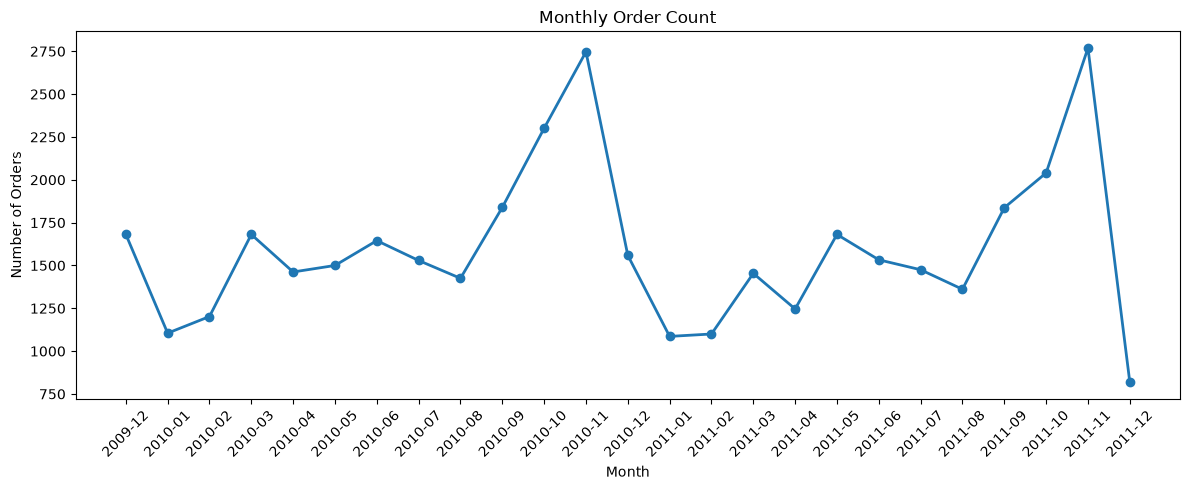

In [37]:
# 3-3 Monthly order chart

plt.figure(figsize=(12,5))

plt.plot(
    monthly_orders["Month"],
    monthly_orders["Order Count"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Order Count")

plt.xlabel("Month")

plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Monthly Order Count

Monthly order counts were caculated to determined whether changes in sales were driven by fluctuations in the number of customer orders.

Tracking order volume helps distinguish between revenue growth resulting from increased purchasing activity and growth driven by higher transaction values.

In [38]:
# 3-4 Monthly Active Customers 

monthly_customers = (
    sales_df
    .dropna(subset=["Customer ID"])
    .groupby("Month")["Customer ID"]
    .nunique()
    .reset_index(name="Active Customer")
)

monthly_customers["Month"] = monthly_customers["Month"].astype(str)

monthly_customers.head()

,Month,Active Customer
0,2009-12,955
1,2010-01,720
2,2010-02,772
3,2010-03,1057
4,2010-04,942


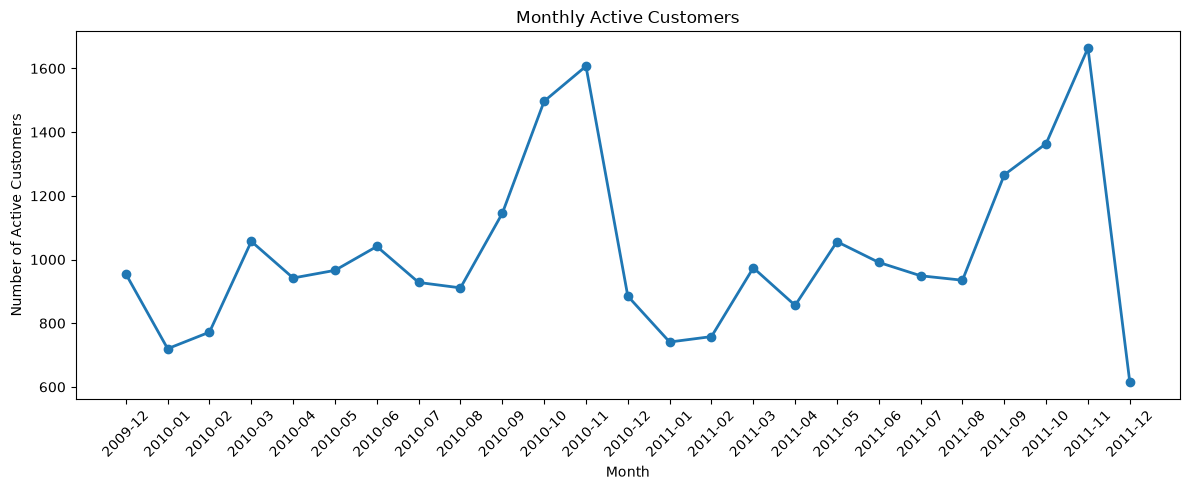

In [39]:
# 3-4 Monthly Active Customer Chart

plt.figure(figsize=(12,5))

plt.plot(
    monthly_customers["Month"],
    monthly_customers["Active Customer"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Active Customers")

plt.xlabel("Month")

plt.ylabel("Number of Active Customers")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Monthly Active Customers

Monthly active customers were measured using unique customer IDs.

This analysis helps determine whether revenue growth is associated with acquiring more customers or changes in customer purchasing behavior.

### Monthly Business Performance

Monthly Sales, Monthly Order Count, and Monthly Active Customers exibit highly consistent trends throughout the observation period.

All three metrics increase substially from September and reach their highest levels in November, suggesting a strong seasonal shopping pattern.

Furthermore, the simultaneous growth of customers, orders, and revenue indicates that business growth is driven by expanding customer activity rather than a small number of exceptional transactions. 

December 2011 contains only partial-month data and should therefore not be interpreted as a decline in business performance.


In [40]:
# 3-5 Average Order Value (AOV)

monthly_aov = monthly_sales.merge(
    monthly_orders,
    on="Month"
)

monthly_aov["AOV"] = (
    monthly_aov["Sales"]/
    monthly_aov["Order Count"]
)

monthly_aov.head()

,Month,Sales,Order Count,AOV
0,2009-12,822483.950,1682,488.991647
1,2010-01,651155.112,1105,589.280644
2,2010-02,551878.296,1202,459.133358
3,2010-03,830915.261,1681,494.298192
4,2010-04,678875.252,1462,464.346958


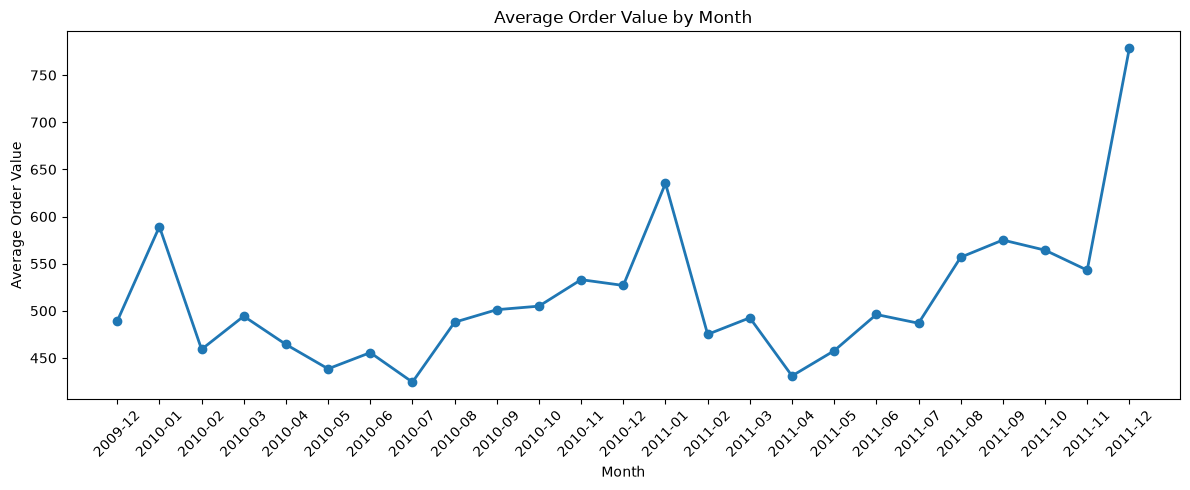

In [41]:
# 3-5 Average Order Value (AOV) Chart

plt.figure(figsize=(12,5))

plt.plot(
    monthly_aov["Month"],
    monthly_aov["AOV"],
    marker = "o",
    linewidth=2
)

plt.title("Average Order Value by Month")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Monthly Average Order Value (AOV)

Average Order Value remained relatively stable throughout most of the analysis period, suggesting that customer spending per order did not change dramatically.

Compared with Sales, Order Count, and Active Customers, the results indicate that revenue growth was primalily driven by increased customer activity rather than substantially higher spending per transaction.

The unusually high AOV observed in December 2011 should be interpreted cautiously because the dataset contains only partial-month data. 

### Business Insight

Monthly business performance demonstrate heathly business growth throught the observation period.

Revenue growth was primarily supported by increases in both order volume and active customers rather than dramatic changes in average order value.

Additionally, the consistent sales peaks observed between September and November suggest a strong seasonal demand pattern, highlighting the importance of inventory planning and marketing campaigns aheds of the year-end shopping season.

In [42]:
# 4-1 Sales by Country

country_sales = (
    sales_df
    .groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending = False)
    .reset_index()
)

country_sales.head(10)

,Country,Sales
0,United Kingdom,1.741057e+07
1,EIRE,6.587673e+05
2,Netherlands,5.540381e+05
3,Germany,4.250197e+05
4,France,3.504561e+05
5,Australia,1.692835e+05
6,Spain,1.083325e+05
7,Switzerland,1.006856e+05
8,Sweden,9.186982e+04
9,Denmark,6.858069e+04


In [43]:
# 4-2 Top 10 Countries 
top10_country_sales = country_sales.head(10)

In [44]:
country_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  43 non-null     str    
 1   Sales    43 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.1 KB


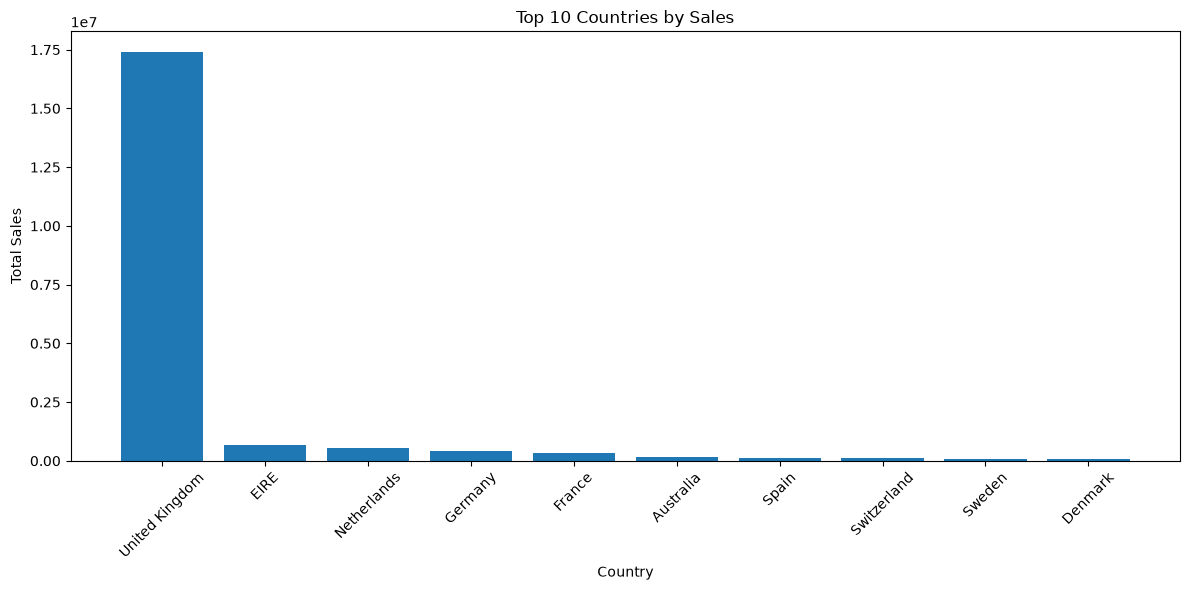

In [45]:
# 4-3 Bar Chart

plt.figure(figsize=(12,6))

plt.bar(
    top10_country_sales["Country"],
    top10_country_sales["Sales"]
)

plt.title("Top 10 Countries by Sales")

plt.xlabel("Country")

plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

##3 Sales by Country

The United Kingdom generates the overwhelming majority of tatal sales, significantly outperforming every other country in the dataseet.

Although several international markets such as EIRE, the Netherlands, Germany, and France contribute meaningful revenue,the business remains highly concentrated in its domestic market.

This geographic concentration suggests opportunities for international expansion while also highlighting potential business risks associated with dependence on a single country. 

In [46]:
# Sales Value excluding UK

country_sales_no_uk = (
    country_sales[country_sales["Country"]!= "United Kingdom"]
    .head(10)
)

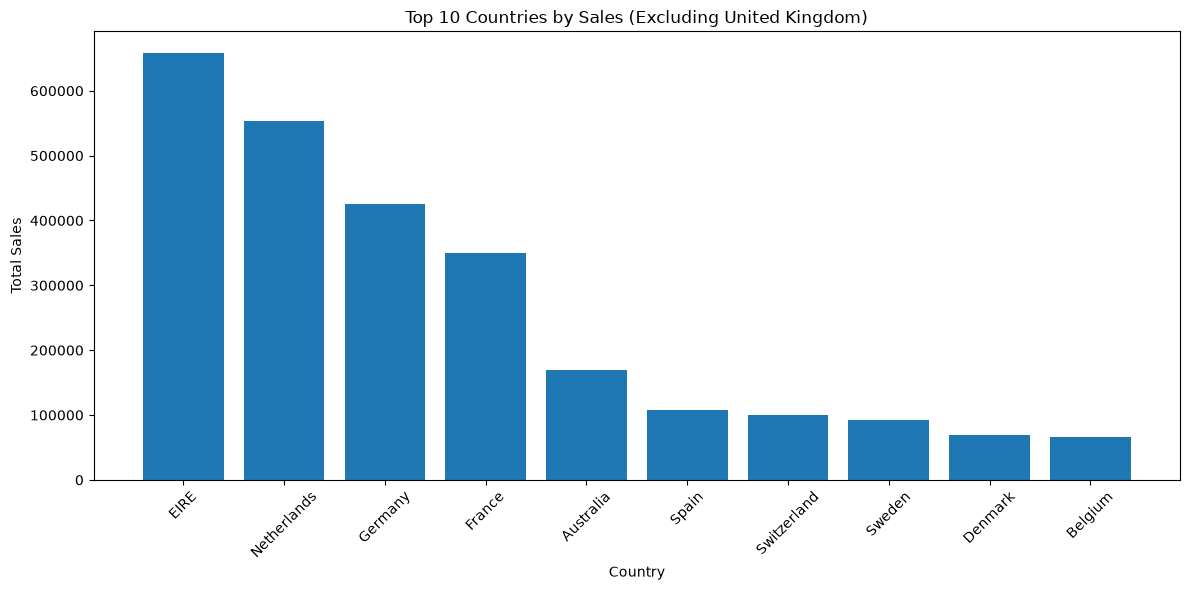

In [47]:
# Chart Excluding UK
plt.figure(figsize=(12,6))

plt.bar(
    country_sales_no_uk["Country"],
    country_sales_no_uk["Sales"]
)

plt.title("Top 10 Countries by Sales (Excluding United Kingdom)")

plt.xlabel("Country")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### International Sales Performance (Excluding United Kingdom)

After excluding the United Kingdom, EIRE emerges as the largest international market, followed by the Netherland, Germany, and France.

International sales are concentrated within a small number of European countries, suggesting that future expansion efforts should prioritize these established markets before entering lower-performing regions.

In [48]:
# 4-2-1 Calculating Unique Customer by Country
country_customers = (
    sales_df
    .groupby("Country")["Customer ID"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Active Customers")
)

country_customers.head(10)

,Country,Active Customers
0,United Kingdom,5350
1,Germany,107
2,France,95
3,Spain,41
4,Belgium,29
5,Portugal,24
6,Switzerland,22
7,Netherlands,22
8,Sweden,19
9,Italy,17


In [49]:
# 4-2-2 Top 10 Countries With the Most Active Customers

top10_country_customers = country_customers.head(10)


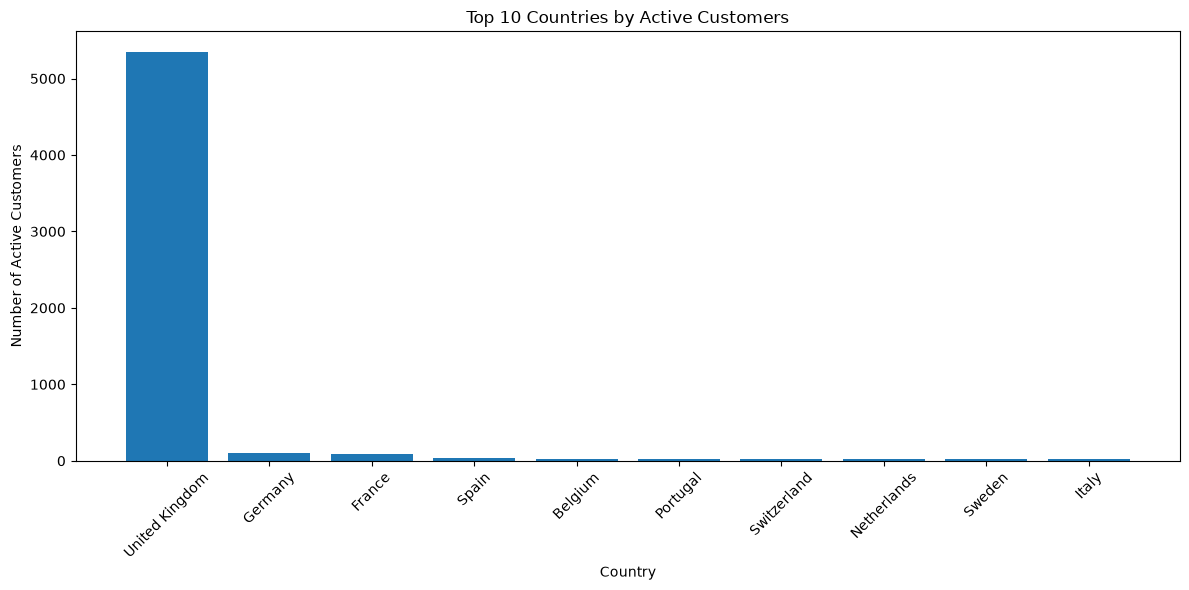

In [50]:
# 4-2-3 Top 10 Countries with the Most Active Customers

plt.figure(figsize=(12,6))

plt.bar(
    top10_country_customers["Country"],
    top10_country_customers["Active Customers"]
)

plt.title("Top 10 Countries by Active Customers")

plt.xlabel("Country")
plt.ylabel("Number of Active Customers")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Active Customers by Country

The United Kingdom has by far the largest active customer base. 

Among international markets, Germany and France have larger customer bases than several countries with higher sales. 

This difference suggests that customer purchasing behavior varies across countries and should be further investigated using Average Order Value (AOV).

In [51]:
# 4-2-4 Top 10 Countries with the Most Active Customers (Excluding UK)

country_customers_no_uk = (
    country_customers[
        country_customers["Country"]!= "United Kingdom"
    ]
    .head(10)
)

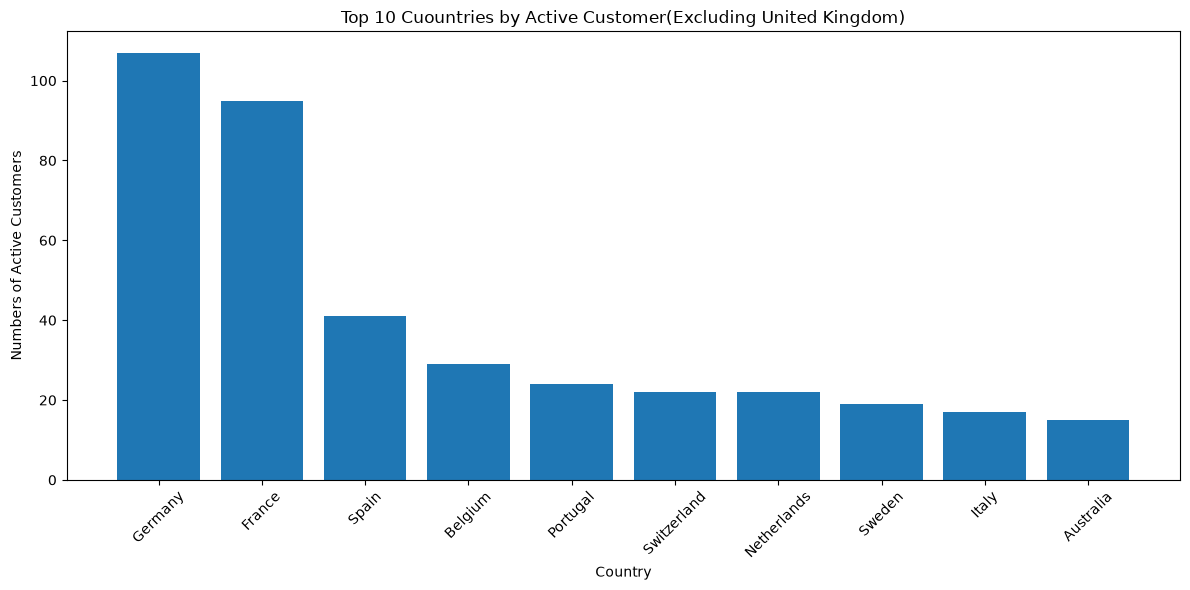

In [52]:
# 4-2-4 Top 10 Countries with the Most Active Customers (Excluding UK)

plt.figure(figsize=(12,6))

plt.bar(
    country_customers_no_uk["Country"],
    country_customers_no_uk["Active Customers"]
)

plt.title("Top 10 Cuountries by Active Customer(Excluding United Kingdom)")

plt.xlabel("Country")
plt.ylabel("Numbers of Active Customers")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### International Active Customers (Excluding United Kingdom)

Germany and France have the largest international customer bases after excluding the United Kingdom.

The ranking of customer counts differs from the ranking of sales, suggesting that purchasing behavior varies across countries.

Markets with many customers may benefit from customer retention strategies, while countries generating high sales with fewer customers may offer opportunities for premium positioning.

## Country Anaysis Summary

The United Kingdom dominates both sales revenue and customer count, confirming its position as the company's primary market.

Among international markets, EIRE generates the highest sales, whereas Germany and France have the largest customer bases.

This difference indicates that customer purchasing behavior varies across countries. Germany and France appear to offer broad customer bases.

Overall, the analysis highlights the importance of adopting country-specific business strategies rather than applying a single global appraoch.

In [53]:
# 4-3-1 Country Average Order Value (AOV) Calculation

country_orders = (
    sales_df
    .groupby("Country")["Invoice"]
    .nunique()
    .reset_index(name="Order Count")
)

country_orders.head()



,Country,Order Count
0,Australia,95
1,Austria,45
2,Bahrain,10
3,Belgium,149
4,Bermuda,1


In [54]:
#4-3-2 Country sales & merge

country_aov = country_sales.merge(
    country_orders,
    on="Country"
)

In [55]:
# 4-3-3 Creating AOV Column

country_aov["AOV"] = (
    country_aov["Sales"]/
    country_aov["Order Count"]
)

country_aov.head()

,Country,Sales,Order Count,AOV
0,United Kingdom,1.741057e+07,36536,476.531905
1,EIRE,6.587673e+05,626,1052.343946
2,Netherlands,5.540381e+05,228,2429.991623
3,Germany,4.250197e+05,789,538.681510
4,France,3.504561e+05,622,563.434228


In [56]:
country_aov.columns

Index(['Country', 'Sales', 'Order Count', 'AOV'], dtype='str')

In [57]:
#4-3-3 Sorting AOV

country_aov = (
    country_aov
    .sort_values(
        by= "AOV",
        ascending=False
    )
)

country_aov.head(10)

,Country,Sales,Order Count,AOV
2,Netherlands,554038.09,228,2429.991623
17,Singapore,25317.06,11,2301.550909
5,Australia,169283.46,95,1781.931158
9,Denmark,68580.69,43,1594.899767
19,Hong Kong,23685.52,15,1579.034667
33,Thailand,3070.54,2,1535.270000
14,Japan,43023.91,33,1303.754848
37,Bermuda,1253.14,1,1253.140000
11,Norway,56322.50,45,1251.611111
31,RSA,4804.32,4,1201.080000


### Country Average Order Value

The Netherlands records the highest Average Order Value among countries with a meaningful number of orders.
EIRE also shows a substantially higher AOV than the United Kingdom, Germany, and France.

Several countries such as Bermuda, Thailand, and RSA appear in the top AOV ranking, but their values are based on very small order counts and should therefore be interpreted cautiously. 

### Interpretation

The country-level analysis confirms that purchasing behavior varies significantly across markets.

Germany and France have relatively large customer bases but lower average order values, while the Netherlands and EIRE generate more revenue per order.

This suggests that international marekts differ not only in customer volume but also in transaction size and pruchasing power.

### Business Insight

The Netherlands represents a particularly attractive international market because it combines high total sales, a meaningful number of orders, and the highest Average Order Value.

EIRE alos demonstrates strong purchasing power per transaction and may respond well to premium product offerings and high_value customer programs.

Germany and France, by contrast, have larger customer bases but lower AOV, suggesting opportunities to increase basket size through cross selling, bundles, and targeted promotions.

Countries with very high AOV but only a few orders should not be prioritized without addtional validation.

In [58]:
#4-3-4 TOP 10 AOV Countries (Countries with Minimum 20 Order counts)

country_aov_filtered = (
    country_aov[
        country_aov["Order Count"] >= 20
    ]
    .sort_values(
        by="AOV",
        ascending=False
    )
)

top10_country_aov_filtered = country_aov_filtered.head(10)

top10_country_aov_filtered

,Country,Sales,Order Count,AOV
2,Netherlands,554038.09,228,2429.991623
5,Australia,169283.46,95,1781.931158
9,Denmark,68580.69,43,1594.899767
14,Japan,43023.91,33,1303.754848
11,Norway,56322.50,45,1251.611111
7,Switzerland,100685.59,93,1082.640753
1,EIRE,658767.31,626,1052.343946
8,Sweden,91869.82,105,874.950667
13,Channel Islands,44623.33,55,811.333273
6,Spain,108332.49,154,703.457727


Countries with fewer than 20 orders were excluded from the comparision to reduce the influence of extremely small samples. 

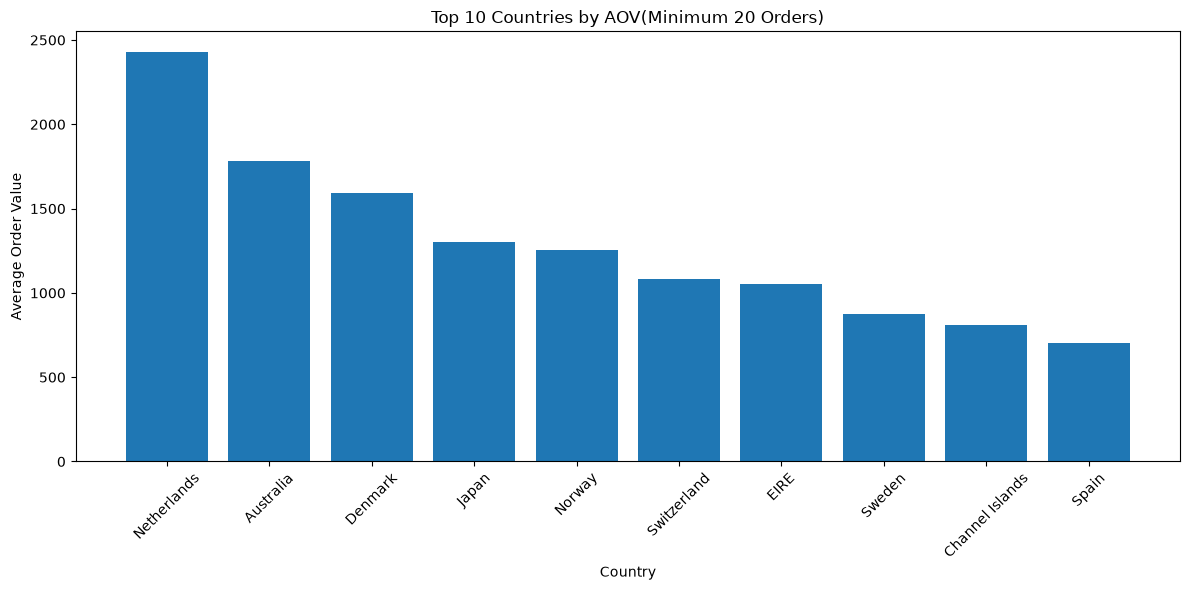

In [59]:
# 4-3-5 TOP AOV Countries (Countries with Minimum 20 Order counts)

plt.figure(figsize=(12,6))

plt.bar(
    top10_country_aov_filtered["Country"],
    top10_country_aov_filtered["AOV"]
)

plt.title("Top 10 Countries by AOV(Minimum 20 Orders)")
plt.xlabel("Country")
plt.ylabel("Average Order Value")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Business Insight

The Netherlands stands out as the strongest high-value international market, combining substial sales with the highest Average Order Value among countries with at least 20 orders.

Australia, Denmark, Japan, and Norway also demonstrate relatively high spending per order and may be suitable for premium product offerings and targeted high-value campaigns.

By contranst, markets with larger customer bases but lower AOV may benefit from cross-selling, product bundles, and promotions designed to increase basket size. 

### Country Average Order Value 

To reduce the influence of extremely samll samples, only countries with at least 20 unique orders were included in the comparision.

The Netherlands records the highest Average Order Value, followed by Australia, Denmark, Japan, and Norway.

These results show that customer spending per transaction differs significantly across international markets. Countries with high AOV may offer opportunities for premium positioning while markets with lower AOV may require strategies focused on increasing basket size. 

In [60]:
# 5-1-1 Top Products by Sales 

product_sales = (
    sales_df
    .groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_sales.head(10)

,Description,Sales
0,Manual,339614.86
1,REGENCY CAKESTAND 3 TIER,330590.32
2,DOTCOM POSTAGE,309854.11
3,WHITE HANGING HEART T-LIGHT HOLDER,260990.22
4,"PAPER CRAFT , LITTLE BIRDIE",168469.60
5,PARTY BUNTING,148318.28
6,JUMBO BAG RED RETROSPOT,148073.47
7,ASSORTED COLOUR BIRD ORNAMENT,129324.49
8,POSTAGE,125682.42
9,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29


In [61]:
# 5-1-2 Top 10 Products by sales

top10_products = product_sales.head(10)

top10_products

,Description,Sales
0,Manual,339614.86
1,REGENCY CAKESTAND 3 TIER,330590.32
2,DOTCOM POSTAGE,309854.11
3,WHITE HANGING HEART T-LIGHT HOLDER,260990.22
4,"PAPER CRAFT , LITTLE BIRDIE",168469.60
5,PARTY BUNTING,148318.28
6,JUMBO BAG RED RETROSPOT,148073.47
7,ASSORTED COLOUR BIRD ORNAMENT,129324.49
8,POSTAGE,125682.42
9,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29


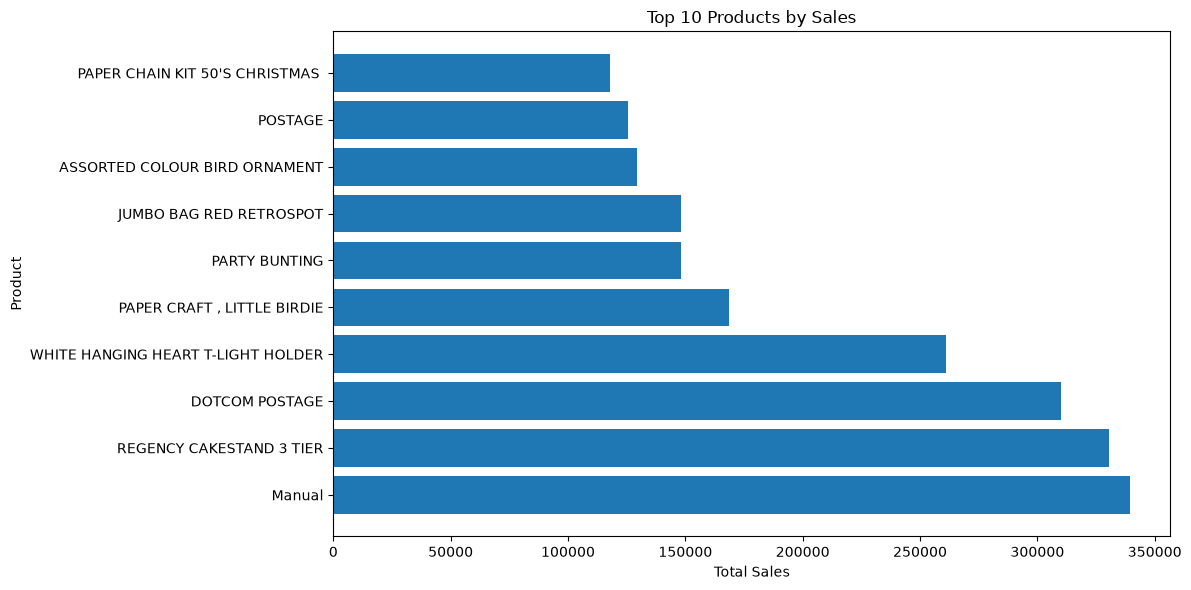

In [62]:
# 5-1-3 Top 10 Products by Sales (chart)

plt.figure(figsize=(12,6))

plt.barh(
    top10_products["Description"],
    top10_products["Sales"]
)

plt.title("Top 10 Products by Sales")

plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.tight_layout()

plt.show()

In [63]:
# 5-1-3 Product Sales exclduing non-product item

non_product_items = [
    "Manual", 
    "DOTCOM POSTAGE",
    "POSTAGE",
    "AMAZONE FEE",
    "Adjust bad debt"
]

product_df = sales_df[
    ~sales_df["Description"].isin(non_product_items)
    ].copy()


In [64]:
product_df[
    product_df["Description"].isin(non_product_items)
].shape

(0, 11)

In [65]:
# 5-1-4 Recalculating sales after excluding non-product items

product_sales_clean = (
    product_df
    .groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

top10_products_clean = product_sales_clean.head(10)

top10_products_clean

,Description,Sales
0,REGENCY CAKESTAND 3 TIER,330590.32
1,WHITE HANGING HEART T-LIGHT HOLDER,260990.22
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,PARTY BUNTING,148318.28
4,JUMBO BAG RED RETROSPOT,148073.47
5,ASSORTED COLOUR BIRD ORNAMENT,129324.49
6,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29
7,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
8,CHILLI LIGHTS,80540.88
9,ROTATING SILVER ANGELS T-LIGHT HLDR,71300.40


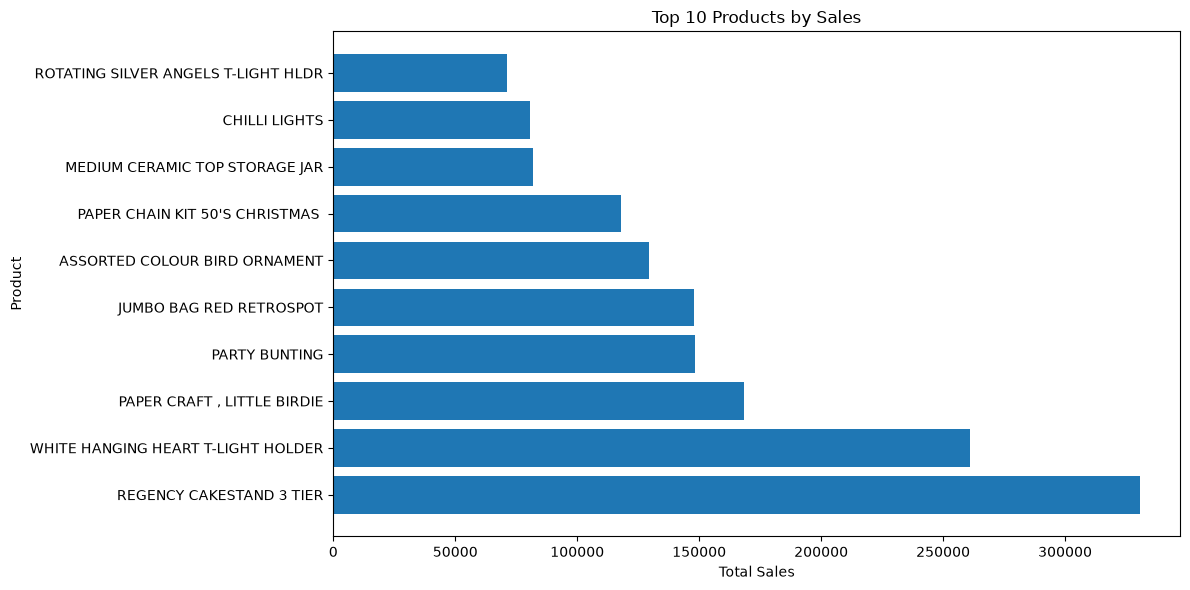

In [66]:
# 5-1-5 Top 10 product by sales (after exclduing non-product)

plt.figure(figsize=(12,6))

plt.barh(
    top10_products_clean["Description"],
    top10_products_clean["Sales"]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.gca().invert_yaxis

plt.tight_layout()
plt.show()


### Business Insight

The company's highest-revenue products are primarily home decoration and lifestyle items.

These products should recieve priority in inventory management, promotional campaigns, and product availability planning. 

However, products with exceptionally large single orders should be evaluated together with sales quantity to distinguish consistently popular products from one-time bulk purchases.

### Top Products by Sales

After excluding non-product records such as postage and manaual adjustments, products were ranked by total sales revenue.

Home decoration and lifestyle products dominate the ranking, with REGENCY CAKESTAND 3TIER ann WHITE HANGING HEART T-LIGHT HOLDER generating the highest revenue.

Some products may rank highly due to unusually large individual orders, so sales quantity analysis is required to validate consistent demand.

In [67]:
# 5-2 Top products by quantity 

product_quantity = (
    product_df
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_quantity.head(10)

,Description,Quantity
0,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139
1,WHITE HANGING HEART T-LIGHT HOLDER,94658
2,"PAPER CRAFT , LITTLE BIRDIE",80995
3,ASSORTED COLOUR BIRD ORNAMENT,80082
4,MEDIUM CERAMIC TOP STORAGE JAR,78033
5,JUMBO BAG RED RETROSPOT,77699
6,BROCADE RING PURSE,70369
7,PACK OF 60 PINK PAISLEY CAKE CASES,56061
8,60 TEATIME FAIRY CAKE CASES,54028
9,SMALL POPCORN HOLDER,48561


In [68]:
# 5-2-2 Top 10 Products by quantity 

top10_quantity = product_quantity.head(10)

top10_quantity

,Description,Quantity
0,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139
1,WHITE HANGING HEART T-LIGHT HOLDER,94658
2,"PAPER CRAFT , LITTLE BIRDIE",80995
3,ASSORTED COLOUR BIRD ORNAMENT,80082
4,MEDIUM CERAMIC TOP STORAGE JAR,78033
5,JUMBO BAG RED RETROSPOT,77699
6,BROCADE RING PURSE,70369
7,PACK OF 60 PINK PAISLEY CAKE CASES,56061
8,60 TEATIME FAIRY CAKE CASES,54028
9,SMALL POPCORN HOLDER,48561


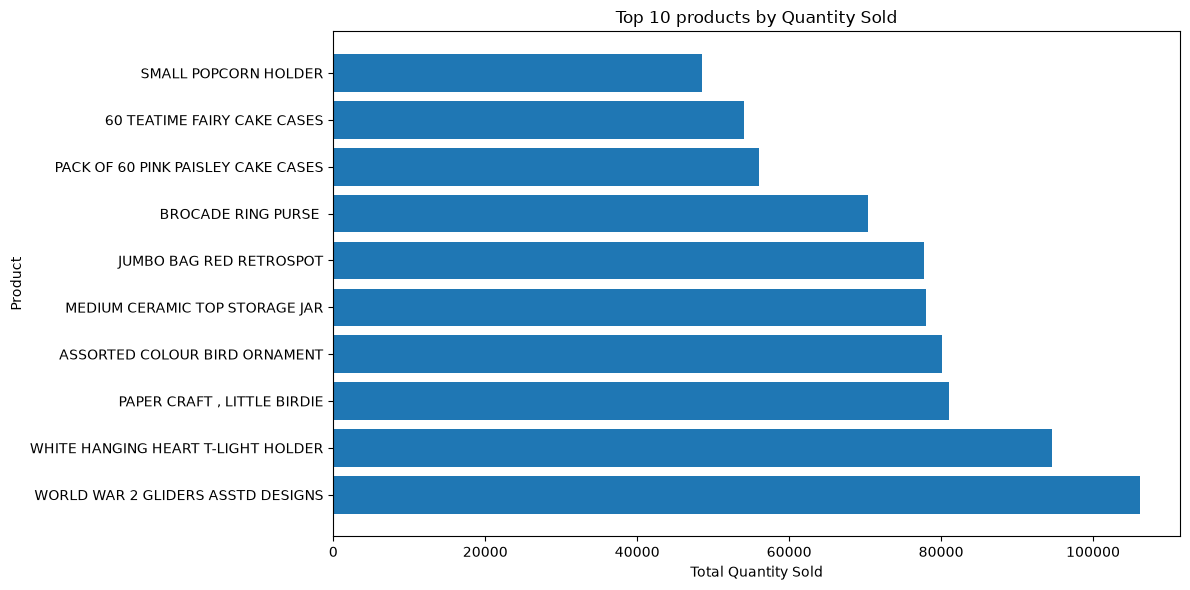

In [69]:
# 5-2-3 Top 10 Product by visualization

plt.figure(figsize=(12,6))

plt.barh(
    top10_quantity["Description"],
    top10_quantity["Quantity"]
)

plt.title("Top 10 products by Quantity Sold")

plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.gca().invert_yaxis

plt.tight_layout()

plt.show()

### Business Insight

Products such as WHITE HANGING HEART T-LIGHT HOLDER and JUMBO BAG RETROSPOT perform strongly is both revenue and sales volume, making them core products for the business.

Products that rank highly in quantity but not in revenue may represent low-priced, high-volume items that attract customers and encourage repeat purchaes.

Conversely, products with high revenue but relatively lower sales volume may be premium-priced products that contribute significantly to profitability.

### Top Products by Quantity Sold

The products with the highest sales volume differ from those generating the highest revenue

This Indicates taht some products succeed through high sales volume, while others contribute more revenue because of higher prices.

Products that rank highly in both revenue and quantity represent the company's strongest core products.

In [ ]:
# 5-3 Preto Analysis
# 1) Confirming Product Sales Ranking 
product_sales_clean.head()

,Description,Sales
0,REGENCY CAKESTAND 3 TIER,330590.32
1,WHITE HANGING HEART T-LIGHT HOLDER,260990.22
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,PARTY BUNTING,148318.28
4,JUMBO BAG RED RETROSPOT,148073.47


In [ ]:
# 5-3 Pareto Analysis 
# 2) Calculating Cumulative Sales
pareto_df = product_sales_clean.copy()

pareto_df["Cumulative Sales"] = (
    pareto_df["Sales"].cumsum()
)

pareto_df["Cumulative Percentage"] = (
    pareto_df["Cumulative Sales"]
    /pareto_df["Sales"].sum()
    *100
)

pareto_df.head()

,Description,Sales,Cumulative Sales,Cumulative Percentage
0,REGENCY CAKESTAND 3 TIER,330590.32,330590.32,1.678940
1,WHITE HANGING HEART T-LIGHT HOLDER,260990.22,591580.54,3.004408
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,760050.14,3.860000
3,PARTY BUNTING,148318.28,908368.42,4.613250
4,JUMBO BAG RED RETROSPOT,148073.47,1056441.89,5.365258


In [72]:
# 5-3 Pareto Analysis 
# 3) How many products are within 80%? 

pareto_80 = pareto_df[
    pareto_df["Cumulative Percentage"] <=80
]

len(pareto_80)

1182

In [73]:
# 5-3 Pareto Analysis
# 4) Ratio to total products
print("Products for 80% Sales :", len(pareto_80))

print("Total Products :", len(pareto_df))

print(
    "Percentage :",
    round(
        len(pareto_80)
        / len(pareto_df)
        *100, 
        2
    ),
    "%"
)

Products for 80% Sales : 1182
Total Products : 5395
Percentage : 21.91 %


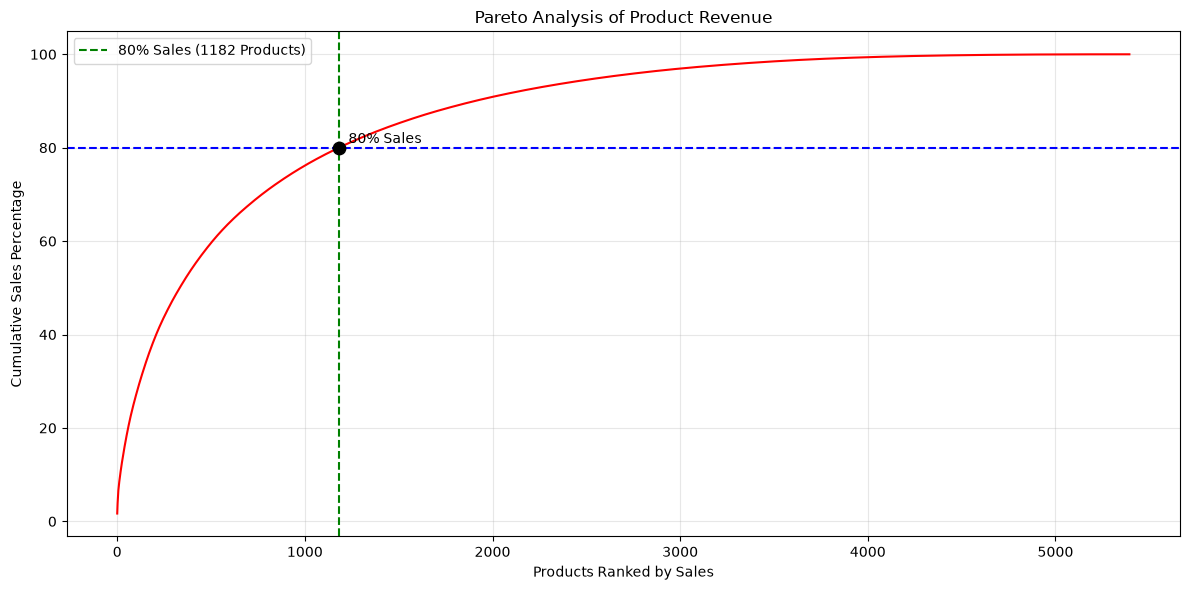

In [74]:
# 5-3 Pareto Analysis
# 5) Pareto Chart

plt.figure(figsize=(12,6))

plt.plot(
    pareto_df["Cumulative Percentage"],
    color="red"
)

plt.axhline(
    y=80,
    color="blue",
    linestyle="--"
)

plt.axvline(
    x=len(pareto_80),
    color="green",
    linestyle="--",
    label=f"80% Sales ({len(pareto_80)} Products)"
)

plt.legend()

plt.scatter(
    len(pareto_80),
    80,
    color="black",
    s=80,
    zorder=5
)

plt.text(
    len(pareto_80)+50,
    81,
    "80% Sales",
    fontsize=10
)

plt.title("Pareto Analysis of Product Revenue")

plt.xlabel("Products Ranked by Sales")

plt.ylabel("Cumulative Sales Percentage")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

### Observation

Approxomately 1,182 out of 5,395 products generate 80% of the company's total sales.

This means that only 21.9% of all products account for majority of business revenue.

### Interpretation 

The product portfolio exhibits a classic Pareto distribution.

A relatively samll subset of products contributes disproportionately to total revenue, while the majority of products generate comparatively smaller sales.

### Business Insight

The Company should prioritize its highest-performing 22% of products for inventory management, demand forecasting, and promotional activities.

These products represent the core revenue drivers and should recieve greater operational focus.

Lower-performing products should be periodically reviewed to determine whether they require promotional support, portfolio optimization, or discontinuation.

### Pareto Analysis (80/20 Rule)

The cumulative sales analysis shows that approximately 1,182 out of 5,395 products generate 80% of the company's total sales.

This represents 21.9% of the entire product portfolio, indicating that the sales distribution closely follows the Pareto Principle.

The result suggests that a relatively small group of products serves as the company's primary revenue drivers.

In [75]:
# 5-4 Product Price Distribution
# 1) Summary Statistics
sales_df["Price"].describe()

count    1.007914e+06
mean     4.074618e+00
std      5.043177e+01
min      1.000000e-03
25%      1.250000e+00
50%      2.100000e+00
75%      4.130000e+00
max      2.511109e+04
Name: Price, dtype: float64

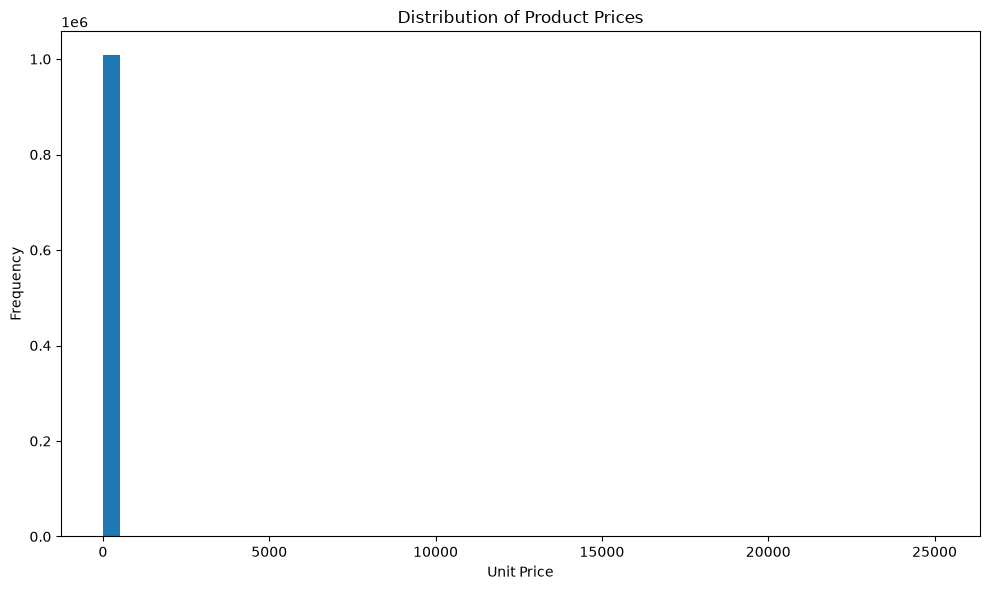

In [76]:
# 5-4 Product Price Distribution
# 2) Price Distribution 
# 5-4-2 Price Distribution

plt.figure(figsize=(10,6))

plt.hist(
    sales_df["Price"],
    bins=50
)

plt.title("Distribution of Product Prices")

plt.xlabel("Unit Price")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

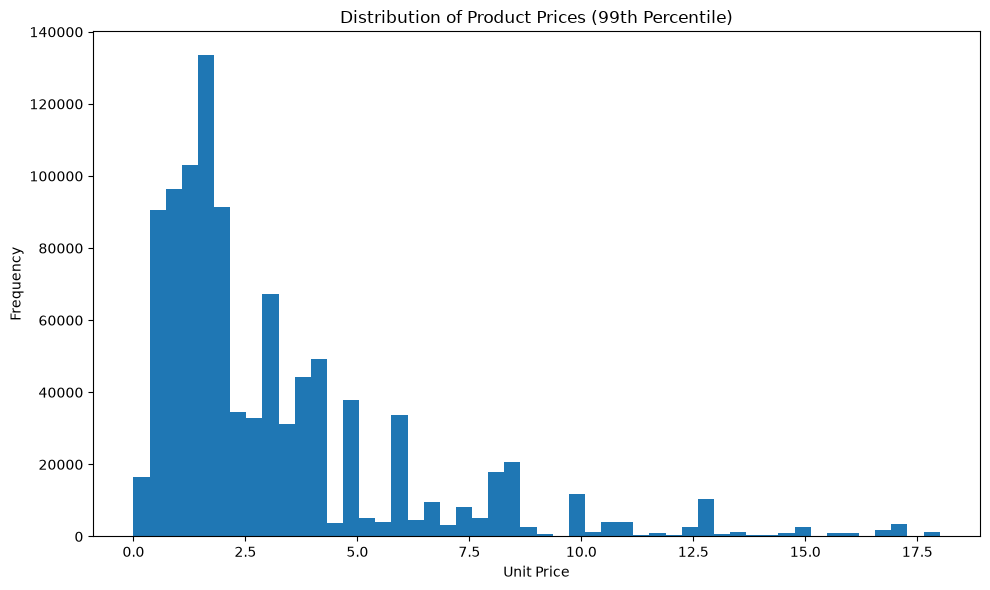

In [77]:
# 5-4 Product Price Distribution
# 2) Price Distribution (Exclduing top 1% of price)
price_limit = sales_df["Price"].quantile(0.99)

plt.figure(figsize=(10,6))

plt.hist(
    sales_df[sales_df["Price"] <= price_limit]["Price"],
    bins=50
)

plt.title("Distribution of Product Prices (99th Percentile)")

plt.xlabel("Unit Price")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

### Observation

The majority of products are priced between approximately ₤1 and ₤3.

Product frequency decreases as price increases, resulting in a right-skewed distribution with only a small number of higher-priced products.

### Interpretation

The business primarily sells low-priced products while maintaining a relatively small selection of premium-priced products.

This pricing structure suggests a retail business focused on high transaction volume rather than high unit prices.

### Business Insight

The company's revenue model appears to rely on selling a large volume of affordable products.

Low-priced products are likely to encourage frequent purchases, while higher-priced products may contribute disproportionately to profit margins.

Maintaining inventory availabilty for popular low-priced products should therefore be a key operational priority.

### Why 99th percentile applied 

Extreme price outliers were excluded using the 99th percentile to better visualize the underlying distribution of typical product prices.

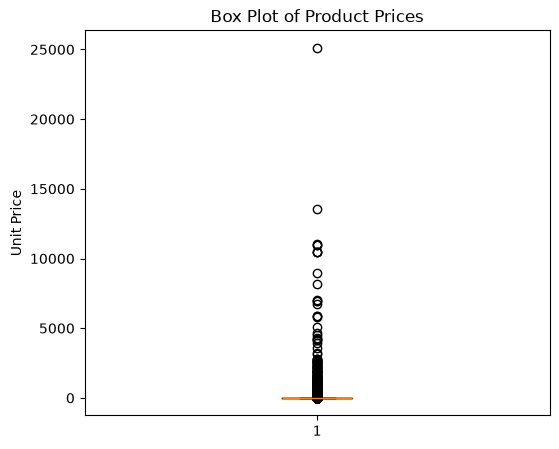

In [78]:
# 5-4 Product Price Box Plot
# 3) Price Box Plot 

plt.figure(figsize=(6,5))

plt.boxplot(sales_df["Price"])

plt.title("Box Plot of Product Prices")

plt.ylabel("Unit Price")

plt.show()


In [79]:
# 5-4 Product Price Box Plot
# 4) Highest Priced Products

sales_df.nlargest(
    10,
    "Price"
)[
    [
        "Description",
        "Price",
        "Quantity",
        "Country"
    ]
]

,Description,Price,Quantity,Country
236866,Manual,25111.09,1,United Kingdom
507980,AMAZON FEE,13541.33,1,United Kingdom
789630,Adjust bad debt,11062.06,1,United Kingdom
132260,Manual,10953.50,1,United Kingdom
132262,Manual,10953.50,1,United Kingdom
335624,Manual,10468.80,1,United Kingdom
351868,Manual,10468.80,1,United Kingdom
365860,Manual,10468.80,1,United Kingdom
73095,Manual,8985.60,1,United Kingdom
664336,POSTAGE,8142.75,1,United Kingdom


### Observation 

Most products are concentrated within a relatively low price range.

The box plot reveals numerous high-priced outliers, but futher investigation shows aht these records are primarily manual adjustments, postage charges, and accounting-related entries rather than actual retail products.

### Interpretation

The apprent high-price outliers do not represent premium retail products.

Instead, they are administrative or accounting records that distort the overall price distribution.

Removing or excluding these records provides a more accurate representation of the company's pricing strategy. 

### Business Insight

The company primarily operates as a low priced retail business.

Extreme price values are largely associated with non-product transactions rather than customer purchases.

Therefore, data cleaning and business-rule validation are essentail before performing pricing pr profitability analyses.

In [85]:

# Slide 06 - Country & Product Revenue Validation

print("=== COUNTRY SALES ===")
print(country_sales.columns.tolist())
display(country_sales.head(5))

print("\n=== PRODUCT PARETO ===")
print(pareto_df.columns.tolist())
display(pareto_df.head(5))

print("\n=== DATASET SIZE ===")
print(f"Countries: {len(country_sales):,}")
print(f"Products: {len(pareto_df):,}")
print(f"Products in Pareto 80 subset: {len(pareto_80):,}")

print(
    f"Pareto subset ratio: "
    f"{len(pareto_80) / len(pareto_df) * 100:.1f}%"
)


=== COUNTRY SALES ===
['Country', 'Sales']


,Country,Sales
0,United Kingdom,1.741057e+07
1,EIRE,6.587673e+05
2,Netherlands,5.540381e+05
3,Germany,4.250197e+05
4,France,3.504561e+05



=== PRODUCT PARETO ===
['Description', 'Sales', 'Cumulative Sales', 'Cumulative Percentage']


,Description,Sales,Cumulative Sales,Cumulative Percentage
0,REGENCY CAKESTAND 3 TIER,330590.32,330590.32,1.678940
1,WHITE HANGING HEART T-LIGHT HOLDER,260990.22,591580.54,3.004408
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,760050.14,3.860000
3,PARTY BUNTING,148318.28,908368.42,4.613250
4,JUMBO BAG RED RETROSPOT,148073.47,1056441.89,5.365258



=== DATASET SIZE ===
Countries: 43
Products: 5,395
Products in Pareto 80 subset: 1,182
Pareto subset ratio: 21.9%


In [86]:

# Slide 06 - Revenue Concentration Validation

# 1. UK revenue share
country_total = country_sales["Sales"].sum()

uk_revenue = country_sales.loc[
    country_sales["Country"] == "United Kingdom",
    "Sales"
].sum()

uk_share = uk_revenue / country_total * 100

print("=== COUNTRY CONCENTRATION ===")
print(f"Country Revenue Total: £{country_total:,.2f}")
print(f"UK Revenue: £{uk_revenue:,.2f}")
print(f"UK Revenue Share: {uk_share:.2f}%")

# 2. Product Pareto validation
product_count = len(pareto_df)
pareto_count = len(pareto_80)

product_share = pareto_count / product_count * 100

print("\n=== PRODUCT CONCENTRATION ===")
print(f"Total Products: {product_count:,}")
print(f"Pareto Products: {pareto_count:,}")
print(f"Product Share: {product_share:.2f}%")

print("\n=== PARETO CUMULATIVE CHECK ===")
print(
    pareto_80["Cumulative Percentage"].min(),
    pareto_80["Cumulative Percentage"].max()
)

# 3. Compare revenue totals
print("\n=== REVENUE BASIS CHECK ===")
print(f"Sales KPI Total: £{total_revenue:,.2f}")
print(f"Country Total: £{country_total:,.2f}")
print(f"Product Total: £{pareto_df['Sales'].sum():,.2f}")


=== COUNTRY CONCENTRATION ===
Country Revenue Total: £20,476,634.02
UK Revenue: £17,410,569.69
UK Revenue Share: 85.03%

=== PRODUCT CONCENTRATION ===
Total Products: 5,395
Pareto Products: 1,182
Product Share: 21.91%

=== PARETO CUMULATIVE CHECK ===
1.6789398624489555 79.998491477625

=== REVENUE BASIS CHECK ===
Sales KPI Total: £20,476,634.02
Country Total: £20,476,634.02
Product Total: £19,690,420.57
